In [2]:
%matplotlib ipympl

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ENTER NODE COORDINATES

In [32]:
nodes = {}

n = int(input("Enter number of nodes: "))

for i in range(1, n + 1):
    x = float(input(f"Enter X coordinate of Node {i}: "))
    y = float(input(f"Enter Y coordinate of Node {i}: "))
    
    nodes[i] = (x, y)

print("\nNode Coordinates")
print("================")

for node, coord in nodes.items():
    print(f"Node {node}: X = {coord[0]}, Y = {coord[1]}")

Enter number of nodes:  4
Enter X coordinate of Node 1:  0
Enter Y coordinate of Node 1:  0
Enter X coordinate of Node 2:  0
Enter Y coordinate of Node 2:  4
Enter X coordinate of Node 3:  6
Enter Y coordinate of Node 3:  0
Enter X coordinate of Node 4:  6
Enter Y coordinate of Node 4:  4



Node Coordinates
Node 1: X = 0.0, Y = 0.0
Node 2: X = 0.0, Y = 4.0
Node 3: X = 6.0, Y = 0.0
Node 4: X = 6.0, Y = 4.0


# STORE CONNECTIVITY

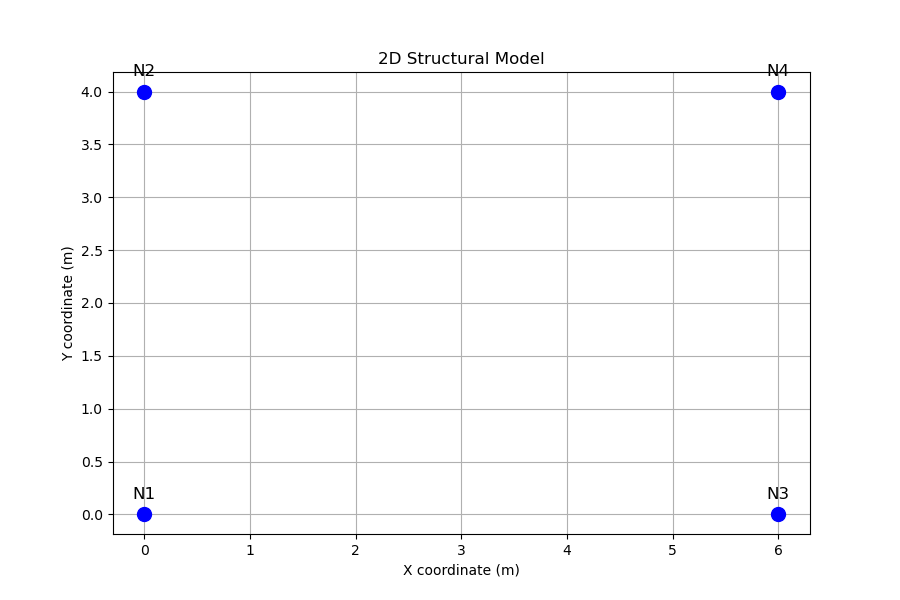

In [33]:
elements = []

# Node currently selected for creating a member
selected_node = None

# Currently highlighted member
selected_member = None


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))


# ============================================================
# DRAW NODES
# ============================================================

x_values = [nodes[i][0] for i in nodes]
y_values = [nodes[i][1] for i in nodes]

ax.scatter(
    x_values,
    y_values,
    s=100,
    color='blue',
    zorder=5
)


# Node labels
for node, (x, y) in nodes.items():

    ax.text(
        x,
        y + 0.15,
        f"N{node}",
        fontsize=12,
        ha='center',
        zorder=6
    )


# ============================================================
# MEMBER GRAPHICS
# ============================================================

member_lines = []
member_labels = []


# ============================================================
# SELECTION GRAPHICS
# ============================================================

selected_arrow = None
selected_i_text = None
selected_j_text = None
selected_info = None


# ============================================================
# ADD MEMBER
# ============================================================

def add_member_graphic(element_id, node_i, node_j):

    xi, yi = nodes[node_i]
    xj, yj = nodes[node_j]

    # --------------------------------------------------------
    # Member line
    # --------------------------------------------------------

    line, = ax.plot(
        [xi, xj],
        [yi, yj],
        color='blue',
        linewidth=2,
        zorder=2
    )

    member_lines.append(line)

    # --------------------------------------------------------
    # Member number
    # --------------------------------------------------------

    xm = (xi + xj) / 2
    ym = (yi + yj) / 2

    label = ax.text(
        xm,
        ym,
        f"E{element_id}",
        fontsize=10,
        color='black',
        ha='center',
        va='center',
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            alpha=0.7
        ),
        zorder=6
    )

    member_labels.append(label)


# ============================================================
# CLEAR SELECTED MEMBER
# ============================================================

def clear_selection():

    global selected_arrow
    global selected_i_text
    global selected_j_text
    global selected_info

    # Restore selected member to normal
    if selected_member is not None:

        member_lines[selected_member - 1].set_color(
            'blue'
        )

        member_lines[selected_member - 1].set_linewidth(
            2
        )

    # Remove arrow
    if selected_arrow is not None:

        selected_arrow.remove()
        selected_arrow = None

    # Remove i-node text
    if selected_i_text is not None:

        selected_i_text.remove()
        selected_i_text = None

    # Remove j-node text
    if selected_j_text is not None:

        selected_j_text.remove()
        selected_j_text = None

    # Remove information box
    if selected_info is not None:

        selected_info.remove()
        selected_info = None


# ============================================================
# SHOW SELECTED MEMBER
# ============================================================

def select_member(element_id):

    global selected_arrow
    global selected_i_text
    global selected_j_text
    global selected_info

    node_i, node_j = elements[element_id - 1]

    xi, yi = nodes[node_i]
    xj, yj = nodes[node_j]

    # --------------------------------------------------------
    # Highlight member
    # --------------------------------------------------------

    member_lines[element_id - 1].set_color(
        'red'
    )

    member_lines[element_id - 1].set_linewidth(
        3
    )

    # --------------------------------------------------------
    # Arrow i → j
    # --------------------------------------------------------

    selected_arrow = ax.annotate(
        "",
        xy=(xj, yj),
        xytext=(xi, yi),

        arrowprops=dict(
            arrowstyle="->",
            linewidth=2.5,
            color="red"
        ),

        zorder=7
    )

    # --------------------------------------------------------
    # i NODE
    # --------------------------------------------------------

    selected_i_text = ax.text(
        xi,
        yi,
        f"  i = N{node_i}",
        fontsize=12,
        color="red",
        fontweight="bold",
        zorder=8
    )

    # --------------------------------------------------------
    # j NODE
    # --------------------------------------------------------

    selected_j_text = ax.text(
        xj,
        yj,
        f"  j = N{node_j}",
        fontsize=12,
        color="red",
        fontweight="bold",
        zorder=8
    )

    # --------------------------------------------------------
    # INFORMATION BOX
    # --------------------------------------------------------

    selected_info = ax.text(
        0.02,
        0.95,

        f"E{element_id}\n"
        f"i-node = N{node_i}\n"
        f"j-node = N{node_j}\n"
        f"Direction: N{node_i} → N{node_j}",

        transform=ax.transAxes,

        fontsize=11,

        verticalalignment='top',

        bbox=dict(
            boxstyle="round",
            facecolor="white",
            edgecolor="red",
            linewidth=1.5
        ),

        zorder=10
    )


# ============================================================
# FIND NODE NEAR CLICK
# ============================================================

def find_node(x_click, y_click):

    closest_node = None
    min_distance = float("inf")

    for node, (x, y) in nodes.items():

        distance = np.sqrt(
            (x - x_click) ** 2 +
            (y - y_click) ** 2
        )

        if distance < min_distance:

            min_distance = distance
            closest_node = node

    # Node click tolerance
    if min_distance < 0.35:

        return closest_node

    return None


# ============================================================
# FIND MEMBER NEAR CLICK
# ============================================================

def find_member(x_click, y_click):

    if len(elements) == 0:

        return None

    closest_member = None
    min_distance = float("inf")

    for element_id, (node_i, node_j) in enumerate(
        elements,
        start=1
    ):

        xi, yi = nodes[node_i]
        xj, yj = nodes[node_j]

        # Member vector
        dx = xj - xi
        dy = yj - yi

        length_squared = dx * dx + dy * dy

        if length_squared == 0:

            continue

        # Projection of click onto member
        t = (
            (x_click - xi) * dx +
            (y_click - yi) * dy
        ) / length_squared

        # Keep projection on member
        t = max(0, min(1, t))

        # Closest point
        closest_x = xi + t * dx
        closest_y = yi + t * dy

        # Distance
        distance = np.sqrt(
            (x_click - closest_x) ** 2 +
            (y_click - closest_y) ** 2
        )

        if distance < min_distance:

            min_distance = distance
            closest_member = element_id

    # Member click tolerance
    if min_distance < 0.25:

        return closest_member

    return None


# ============================================================
# MOUSE CLICK
# ============================================================

def onclick(event):

    global selected_node
    global selected_member

    # Ignore clicks outside graph
    if (
        event.xdata is None
        or event.ydata is None
    ):

        return

    x = event.xdata
    y = event.ydata


    # ========================================================
    # 1. CHECK NODE FIRST
    # ========================================================

    node = find_node(x, y)

    if node is not None:

        # If a member is currently selected,
        # remove its visual selection.
        if selected_member is not None:

            clear_selection()

            selected_member = None

            fig.canvas.draw_idle()


        # ----------------------------------------------------
        # FIRST NODE
        # ----------------------------------------------------

        if selected_node is None:

            selected_node = node

            print(
                f"Node N{node} selected."
            )

            print(
                "Click another node to create member."
            )

            return


        # ----------------------------------------------------
        # SECOND NODE
        # ----------------------------------------------------

        node_i = selected_node
        node_j = node


        # Same node
        if node_i == node_j:

            print(
                "Cannot connect a node to itself."
            )

            selected_node = None

            return


        # ----------------------------------------------------
        # CHECK DUPLICATE
        # ----------------------------------------------------

        connection = tuple(
            sorted(
                (node_i, node_j)
            )
        )

        existing_connections = [

            tuple(
                sorted(e)
            )

            for e in elements
        ]


        if connection in existing_connections:

            print(
                f"Member N{node_i}-N{node_j} "
                "already exists."
            )

            selected_node = None

            return


        # ----------------------------------------------------
        # CREATE MEMBER
        # ----------------------------------------------------

        elements.append(
            (node_i, node_j)
        )

        element_id = len(elements)


        print()
        print(
            f"Member E{element_id} created"
        )
        print(
            f"i-node = N{node_i}"
        )
        print(
            f"j-node = N{node_j}"
        )
        print(
            f"Direction = N{node_i} → N{node_j}"
        )
        print()


        # Draw only new member
        add_member_graphic(
            element_id,
            node_i,
            node_j
        )


        # Reset node selection
        selected_node = None

        fig.canvas.draw_idle()

        return


    # ========================================================
    # 2. CHECK MEMBER
    # ========================================================

    member = find_member(x, y)


    if member is not None:

        # ----------------------------------------------------
        # CLICK SAME MEMBER AGAIN
        # → NORMAL
        # ----------------------------------------------------

        if selected_member == member:

            clear_selection()

            selected_member = None

            fig.canvas.draw_idle()

            print(
                f"E{member} deselected."
            )

            return


        # ----------------------------------------------------
        # CLICK DIFFERENT MEMBER
        # → SELECT NEW MEMBER
        # ----------------------------------------------------

        if selected_member is not None:

            clear_selection()


        selected_member = member

        select_member(member)

        node_i, node_j = elements[
            member - 1
        ]

        print()
        print(
            f"E{member} selected"
        )
        print(
            f"i-node = N{node_i}"
        )
        print(
            f"j-node = N{node_j}"
        )
        print(
            f"Direction = N{node_i} → N{node_j}"
        )
        print()

        fig.canvas.draw_idle()

        return


# ============================================================
# CONNECT MOUSE
# ============================================================

cid = fig.canvas.mpl_connect(
    'button_press_event',
    onclick
)


# ============================================================
# GRAPH SETTINGS
# ============================================================

ax.set_xlabel(
    "X coordinate (m)"
)

ax.set_ylabel(
    "Y coordinate (m)"
)

ax.set_title(
    "2D Structural Model"
)

ax.grid(True)

ax.axis("equal")


# ============================================================
# SHOW
# ============================================================

plt.show()

In [34]:
print("\n================================")
print("AUTOMATIC CONNECTIVITY")
print("================================")

for i, (node_i, node_j) in enumerate(elements, start=1):
    print(f"Element {i}: Node {node_i} → Node {node_j}")


AUTOMATIC CONNECTIVITY
Element 1: Node 1 → Node 2
Element 2: Node 2 → Node 4
Element 3: Node 4 → Node 3


# Select STRUCTURE TYPE

In [35]:
print("======================================")
print("       2D STRUCTURAL ANALYZER")
print("======================================")

print("\nSelect structural type:")
print("1 - 2D Truss")
print("2 - 2D Frame")

structure_type = int(input("\nEnter choice (1 or 2): "))

if structure_type == 1:
    element_type = "TRUSS"

elif structure_type == 2:
    element_type = "FRAME"

else:
    raise ValueError("Invalid choice")

print("\nSelected structure:", element_type)

       2D STRUCTURAL ANALYZER

Select structural type:
1 - 2D Truss
2 - 2D Frame



Enter choice (1 or 2):  2



Selected structure: FRAME


# MATERIAL AND SECTION PROPERTIES

In [42]:
print("======================================")
print("       MATERIAL PROPERTIES")
print("======================================")

E = float(input("Young's modulus E (Pa): "))

A = float(input("Cross-sectional area A (m²): "))

if element_type == "FRAME":

    I = float(
        input("Second moment of area I (m⁴): ")
    )

else:

    I = None

print("\nProperties entered:")
print(f"E = {E:.3e} Pa")
print(f"A = {A:.3e} m²")

if element_type == "FRAME":

    print(f"I = {I:.3e} m⁴")

       MATERIAL PROPERTIES


Young's modulus E (Pa):  2e11
Cross-sectional area A (m²):  5e-3
Second moment of area I (m⁴):  2e-4



Properties entered:
E = 2.000e+11 Pa
A = 5.000e-03 m²
I = 2.000e-04 m⁴


# SUPPORT ASSIGNMENT

In [43]:
%gui qt5

In [66]:
# ============================================================
# CELL 6 : SUPPORT ASSIGNMENT - PYQTGRAPH VERSION
# ============================================================

import numpy as np
import pyqtgraph as pg
from PyQt5 import QtWidgets, QtCore


# ============================================================
# SUPPORT DATA
# ============================================================

supports = {node: "FREE" for node in nodes}

support_angles = {
    node: 0.0
    for node in nodes
}


# ============================================================
# QT APPLICATION
# ============================================================

app = pg.mkQApp(
    "2D FEM Support Assignment"
)


# ============================================================
# MAIN WINDOW
# ============================================================

window = QtWidgets.QMainWindow()

window.setWindowTitle(
    "2D Structural Model - Support Assignment"
)

window.resize(
    1250,
    750
)

central = QtWidgets.QWidget()

window.setCentralWidget(
    central
)

main_layout = QtWidgets.QHBoxLayout(
    central
)

main_layout.setContentsMargins(
    8,
    8,
    8,
    8
)


# ============================================================
# STRUCTURE VIEW
# ============================================================

plot = pg.PlotWidget()

plot.setBackground("w")

plot.showGrid(
    x=True,
    y=True,
    alpha=0.25
)

plot.setLabel(
    "bottom",
    "X coordinate",
    units="m"
)

plot.setLabel(
    "left",
    "Y coordinate",
    units="m"
)

plot.setTitle(
    "2D Structural Model - Support Assignment"
)

plot.setAspectLocked(
    True
)

main_layout.addWidget(
    plot,
    1
)


# ============================================================
# RIGHT PANEL
# ============================================================

panel = QtWidgets.QFrame()

panel.setFixedWidth(
    280
)

panel_layout = QtWidgets.QVBoxLayout(
    panel
)

main_layout.addWidget(
    panel
)


# ============================================================
# TITLE
# ============================================================

title = QtWidgets.QLabel(
    "SUPPORT ASSIGNMENT"
)

title.setAlignment(
    QtCore.Qt.AlignCenter
)

title.setStyleSheet(
    """
    QLabel {
        font-size: 17px;
        font-weight: bold;
        padding: 10px;
    }
    """
)

panel_layout.addWidget(
    title
)


# ============================================================
# INFORMATION BOX
# ============================================================

info = QtWidgets.QLabel(
    "No node selected"
)

info.setAlignment(
    QtCore.Qt.AlignTop
)

info.setWordWrap(
    True
)

info.setMinimumHeight(
    90
)

info.setStyleSheet(
    """
    QLabel {
        border: 1px solid #999;
        padding: 10px;
        background: #f7f7f7;
        font-size: 14px;
    }
    """
)

panel_layout.addWidget(
    info
)


# ============================================================
# SUPPORT TYPE
# ============================================================

label = QtWidgets.QLabel(
    "Select Support Type:"
)

label.setStyleSheet(
    "font-weight: bold;"
)

panel_layout.addWidget(
    label
)


# ============================================================
# BUTTON FUNCTION
# ============================================================

def create_button(text):

    button = QtWidgets.QPushButton(
        text
    )

    button.setMinimumHeight(
        42
    )

    button.setStyleSheet(
        """
        QPushButton {
            font-size: 14px;
        }
        """
    )

    panel_layout.addWidget(
        button
    )

    return button


btn_free = create_button(
    "FREE"
)

btn_pin = create_button(
    "PIN"
)

btn_roller = create_button(
    "ROLLER"
)

btn_fixed = create_button(
    "FIXED"
)


# ============================================================
# SUPPORT ANGLE
# ============================================================

angle_label = QtWidgets.QLabel(
    "Support Angle θ (° from horizontal):"
)

angle_label.setStyleSheet(
    "font-weight: bold;"
)

panel_layout.addWidget(
    angle_label
)

angle_input = QtWidgets.QLineEdit(
    "0"
)

angle_input.setMinimumHeight(
    35
)

panel_layout.addWidget(
    angle_input
)


# ============================================================
# APPLY
# ============================================================

btn_apply = QtWidgets.QPushButton(
    "APPLY"
)

btn_apply.setMinimumHeight(
    45
)

btn_apply.setStyleSheet(
    """
    QPushButton {
        font-size: 15px;
        font-weight: bold;
    }
    """
)

panel_layout.addWidget(
    btn_apply
)


# ============================================================
# INSTRUCTIONS
# ============================================================

instructions = QtWidgets.QLabel(
    """
    <b>How to use:</b><br><br>
    1. Click a node<br>
    2. Select support type<br>
    3. Enter support angle θ<br>
    4. Click APPLY<br><br>

    <b>Angle θ:</b><br>
    Measured counter-clockwise
    from the horizontal X-axis.<br><br>

    <b>Reference:</b><br>
    θ = 0° → horizontal support surface<br>
    θ = 90° → vertical support surface
    """
)

instructions.setWordWrap(
    True
)

instructions.setStyleSheet(
    """
    QLabel {
        padding: 8px;
        font-size: 12px;
    }
    """
)

panel_layout.addWidget(
    instructions
)

panel_layout.addStretch()


# ============================================================
# DRAW MEMBERS
# ============================================================

for element_id, (
    node_i,
    node_j
) in enumerate(
    elements,
    start=1
):

    xi, yi = nodes[node_i]

    xj, yj = nodes[node_j]

    # --------------------------------------------------------
    # MEMBER
    # --------------------------------------------------------

    member = pg.PlotDataItem(
        [xi, xj],
        [yi, yj],
        pen=pg.mkPen(
            "b",
            width=2
        )
    )

    plot.addItem(
        member
    )

    # --------------------------------------------------------
    # MEMBER LABEL
    # --------------------------------------------------------

    xm = (
        xi + xj
    ) / 2

    ym = (
        yi + yj
    ) / 2

    member_label = pg.TextItem(
        f"E{element_id}",
        color="k",
        anchor=(0.5, 0.5)
    )

    member_label.setPos(
        xm,
        ym
    )

    plot.addItem(
        member_label
    )


# ============================================================
# DRAW NODES
# ============================================================

node_numbers = list(
    nodes.keys()
)

node_x = [
    nodes[n][0]
    for n in node_numbers
]

node_y = [
    nodes[n][1]
    for n in node_numbers
]


node_scatter = pg.ScatterPlotItem(
    x=node_x,
    y=node_y,
    size=16,
    brush=pg.mkBrush(
        0,
        0,
        255
    ),
    pen=pg.mkPen(
        "b",
        width=1
    ),
    hoverable=True,
    hoverSize=20
)

plot.addItem(
    node_scatter
)


# ============================================================
# NODE LABELS
# ============================================================

for node, (
    x,
    y
) in nodes.items():

    text = pg.TextItem(
        f"N{node}",
        color="k",
        anchor=(0.5, 1.5)
    )

    text.setPos(
        x,
        y
    )

    plot.addItem(
        text
    )


# ============================================================
# SELECTED NODE MARKER
# ============================================================

selected_marker = pg.ScatterPlotItem(
    size=28,
    brush=None,
    pen=pg.mkPen(
        "r",
        width=3
    )
)

plot.addItem(
    selected_marker
)


# ============================================================
# VARIABLES
# ============================================================

selected_node = None

pending_type = "FREE"

support_graphics = {}


# ============================================================
# UPDATE INFORMATION
# ============================================================

def update_info():

    if selected_node is None:

        info.setText(
            "No node selected"
        )

        return

    current = supports[
        selected_node
    ]

    angle = support_angles[
        selected_node
    ]

    info.setText(
        f"""
        <b>Selected Node:</b> N{selected_node}<br><br>
        <b>Current Support:</b> {current}<br>
        <b>Support Angle θ:</b> {angle:.1f}°<br>
        <b>Pending:</b> {pending_type}
        """
    )


# ============================================================
# NODE CLICK
# ============================================================

def node_clicked(
    scatter,
    points
):

    global selected_node
    global pending_type

    if not points:
        return

    point = points[0]

    # --------------------------------------------------------
    # NODE NUMBER STORED IN POINT DATA
    # --------------------------------------------------------

    node = point.data()

    if node is None:
        return

    selected_node = int(
        node
    )

    # --------------------------------------------------------
    # CURRENT SUPPORT BECOMES SELECTED TYPE
    # --------------------------------------------------------

    pending_type = supports[
        selected_node
    ]

    # --------------------------------------------------------
    # SHOW CURRENT ANGLE
    # --------------------------------------------------------

    angle_input.setText(
        str(
            support_angles[
                selected_node
            ]
        )
    )

    # --------------------------------------------------------
    # RED SELECTION CIRCLE
    # --------------------------------------------------------

    x, y = nodes[
        selected_node
    ]

    selected_marker.setData(
        [x],
        [y]
    )

    update_info()

    print(
        f"Selected Node N{selected_node}"
    )


# ============================================================
# ADD NODE IDs TO SCATTER DATA
# ============================================================

node_spots = []

for node in node_numbers:

    node_spots.append(
        {
            "pos": nodes[node],
            "data": node
        }
    )


node_scatter.setData(
    spots=node_spots,
    size=16,
    brush=pg.mkBrush(
        0,
        0,
        255
    ),
    pen=pg.mkPen(
        "b"
    )
)


# ============================================================
# CONNECT DIRECT NODE CLICK
# ============================================================

node_scatter.sigClicked.connect(
    node_clicked
)


# ============================================================
# REMOVE OLD SUPPORT GRAPHIC
# ============================================================

def remove_support_graphic(node):

    if node not in support_graphics:

        return

    for item in support_graphics[
        node
    ]:

        plot.removeItem(
            item
        )

    del support_graphics[
        node
    ]


# ============================================================
# DRAW LINE
# ============================================================

def draw_line(
    x,
    y
):

    item = pg.PlotDataItem(
        x,
        y,
        pen=pg.mkPen(
            "k",
            width=2
        )
    )

    plot.addItem(
        item
    )

    return item


# ============================================================
# PIN SUPPORT
# ============================================================

def draw_pin(
    node,
    angle
):

    x, y = nodes[node]

    s = 0.45

    items = []

    # --------------------------------------------------------
    # PIN CIRCLE
    # --------------------------------------------------------

    theta = np.linspace(
        0,
        2 * np.pi,
        40
    )

    circle_r = 0.14 * s

    circle_x = (
        circle_r * np.cos(theta)
    )

    circle_y = (
        circle_r * np.sin(theta)
    )

    X = []
    Y = []

    for px, py in zip(
        circle_x,
        circle_y
    ):

        rx, ry = rotate_point(
            px,
            py,
            angle
        )

        X.append(
            x + rx
        )

        Y.append(
            y + ry
        )

    items.append(
        draw_line(
            X,
            Y
        )
    )

    # --------------------------------------------------------
    # PIN TRIANGLE
    #
    # θ = 0°:
    #
    #          ○
    #          /\
    #         /  \
    #        ------
    #
    # Support surface is horizontal.
    # --------------------------------------------------------

    local_points = [

        (-s, -0.55 * s),

        (0, -0.05 * s),

        (s, -0.55 * s),

        (-s, -0.55 * s)

    ]

    X = []
    Y = []

    for px, py in local_points:

        rx, ry = rotate_point(
            px,
            py,
            angle
        )

        X.append(
            x + rx
        )

        Y.append(
            y + ry
        )

    items.append(
        draw_line(
            X,
            Y
        )
    )

    # --------------------------------------------------------
    # GROUND / SUPPORT SURFACE
    # --------------------------------------------------------

    p1 = rotate_point(
        -1.25 * s,
        -0.55 * s,
        angle
    )

    p2 = rotate_point(
        1.25 * s,
        -0.55 * s,
        angle
    )

    items.append(
        draw_line(
            [
                x + p1[0],
                x + p2[0]
            ],
            [
                y + p1[1],
                y + p2[1]
            ]
        )
    )

    # --------------------------------------------------------
    # GROUND HATCHING
    # --------------------------------------------------------

    for dx in np.linspace(
        -s,
        s,
        7
    ):

        p1 = rotate_point(
            dx,
            -0.55 * s,
            angle
        )

        p2 = rotate_point(
            dx - 0.18,
            -0.55 * s - 0.20,
            angle
        )

        items.append(
            draw_line(
                [
                    x + p1[0],
                    x + p2[0]
                ],
                [
                    y + p1[1],
                    y + p2[1]
                ]
            )
        )

    return items


# ============================================================
# ROTATION FUNCTION
# ============================================================

def rotate_point(
    px,
    py,
    angle
):

    a = np.radians(
        angle
    )

    return (
        px * np.cos(a)
        - py * np.sin(a),

        px * np.sin(a)
        + py * np.cos(a)
    )


# ============================================================
# ROLLER SUPPORT
# ============================================================

def draw_roller(
    node,
    angle
):

    x, y = nodes[node]

    s = 0.45

    items = []

    # --------------------------------------------------------
    # TRIANGLE
    #
    # θ = 0° → horizontal support surface
    # --------------------------------------------------------

    local_points = [

        (-s, -0.35 * s),

        (0, 0),

        (s, -0.35 * s),

        (-s, -0.35 * s)

    ]

    X = []

    Y = []

    for px, py in local_points:

        rx, ry = rotate_point(
            px,
            py,
            angle
        )

        X.append(
            x + rx
        )

        Y.append(
            y + ry
        )

    items.append(
        draw_line(
            X,
            Y
        )
    )

    # --------------------------------------------------------
    # ROLLERS
    # --------------------------------------------------------

    for px in [
        -0.45 * s,
        0,
        0.45 * s
    ]:

        rx, ry = rotate_point(
            px,
            -0.58 * s,
            angle
        )

        theta = np.linspace(
            0,
            2 * np.pi,
            20
        )

        local_cx = (
            rx
            + 0.11 * np.cos(theta)
        )

        local_cy = (
            ry
            + 0.11 * np.sin(theta)
        )

        X = []
        Y = []

        for cx, cy in zip(
            local_cx,
            local_cy
        ):

            rrx, rry = rotate_point(
                cx - rx,
                cy - ry,
                angle
            )

            X.append(
                x + rx + rrx
            )

            Y.append(
                y + ry + rry
            )

        items.append(
            draw_line(
                X,
                Y
            )
        )

    # --------------------------------------------------------
    # GROUND / SUPPORT SURFACE
    # --------------------------------------------------------

    p1 = rotate_point(
        -1.0 * s,
        -0.80 * s,
        angle
    )

    p2 = rotate_point(
        1.0 * s,
        -0.80 * s,
        angle
    )

    items.append(
        draw_line(
            [
                x + p1[0],
                x + p2[0]
            ],
            [
                y + p1[1],
                y + p2[1]
            ]
        )
    )

    return items


# ============================================================
# FIXED SUPPORT
# ============================================================

def draw_fixed(
    node,
    angle
):

    x, y = nodes[node]

    s = 0.5

    items = []

    # --------------------------------------------------------
    # FIXED WALL
    #
    # IMPORTANT:
    #
    # θ = 0°  → horizontal support surface
    #            therefore wall is vertical
    #
    # θ = 90° → vertical support surface
    #            therefore wall is horizontal
    # --------------------------------------------------------

    wall_angle = angle + 90.0

    p1 = rotate_point(
        0,
        -s,
        wall_angle
    )

    p2 = rotate_point(
        0,
        s,
        wall_angle
    )

    items.append(
        draw_line(
            [
                x + p1[0],
                x + p2[0]
            ],
            [
                y + p1[1],
                y + p2[1]
            ]
        )
    )

    # --------------------------------------------------------
    # FIXED WALL HATCHING
    # --------------------------------------------------------

    for yy in np.linspace(
        -s,
        s,
        8
    ):

        p1 = rotate_point(
            0,
            yy,
            wall_angle
        )

        p2 = rotate_point(
            -0.25,
            yy - 0.18,
            wall_angle
        )

        items.append(
            draw_line(
                [
                    x + p1[0],
                    x + p2[0]
                ],
                [
                    y + p1[1],
                    y + p2[1]
                ]
            )
        )

    return items


# ============================================================
# DRAW SUPPORT
# ============================================================

def draw_support(node):

    # --------------------------------------------------------
    # REMOVE OLD GRAPHIC
    # --------------------------------------------------------

    remove_support_graphic(
        node
    )

    support_type = supports[
        node
    ]

    angle = support_angles[
        node
    ]

    # --------------------------------------------------------
    # FREE
    # --------------------------------------------------------

    if support_type == "FREE":

        return

    # --------------------------------------------------------
    # PIN
    # --------------------------------------------------------

    if support_type == "PIN":

        items = draw_pin(
            node,
            angle
        )

    # --------------------------------------------------------
    # ROLLER
    # --------------------------------------------------------

    elif support_type == "ROLLER":

        items = draw_roller(
            node,
            angle
        )

    # --------------------------------------------------------
    # FIXED
    # --------------------------------------------------------

    elif support_type == "FIXED":

        items = draw_fixed(
            node,
            angle
        )

    else:

        return

    support_graphics[
        node
    ] = items


# ============================================================
# SUPPORT TYPE BUTTONS
# ============================================================

def choose_free():

    global pending_type

    pending_type = "FREE"

    update_info()


def choose_pin():

    global pending_type

    pending_type = "PIN"

    update_info()


def choose_roller():

    global pending_type

    pending_type = "ROLLER"

    update_info()


def choose_fixed():

    global pending_type

    pending_type = "FIXED"

    update_info()


btn_free.clicked.connect(
    choose_free
)

btn_pin.clicked.connect(
    choose_pin
)

btn_roller.clicked.connect(
    choose_roller
)

btn_fixed.clicked.connect(
    choose_fixed
)


# ============================================================
# APPLY SUPPORT
# ============================================================

def apply_support():

    global selected_node

    if selected_node is None:

        info.setText(
            "Please click a node first."
        )

        return

    # --------------------------------------------------------
    # READ SUPPORT ANGLE
    # --------------------------------------------------------

    try:

        angle = float(
            angle_input.text()
        )

    except ValueError:

        info.setText(
            "Invalid angle. Enter a number."
        )

        return

    # --------------------------------------------------------
    # NORMALIZE ANGLE
    # --------------------------------------------------------

    angle = angle % 360

    # --------------------------------------------------------
    # SAVE SUPPORT
    # --------------------------------------------------------

    supports[
        selected_node
    ] = pending_type

    support_angles[
        selected_node
    ] = angle

    # --------------------------------------------------------
    # DRAW SUPPORT
    # --------------------------------------------------------

    draw_support(
        selected_node
    )

    # --------------------------------------------------------
    # UPDATE INFORMATION
    # --------------------------------------------------------

    update_info()

    # --------------------------------------------------------
    # CONSOLE OUTPUT
    # --------------------------------------------------------

    print(
        f"N{selected_node} : "
        f"{pending_type} | "
        f"θ = {angle:.2f}°"
    )


btn_apply.clicked.connect(
    apply_support
)


# ============================================================
# INITIAL VIEW
# ============================================================

if nodes:

    xs = [
        nodes[n][0]
        for n in nodes
    ]

    ys = [
        nodes[n][1]
        for n in nodes
    ]

    xmin = min(xs)

    xmax = max(xs)

    ymin = min(ys)

    ymax = max(ys)

    dx = max(
        (xmax - xmin) * 0.15,
        0.5
    )

    dy = max(
        (ymax - ymin) * 0.15,
        0.5
    )

    plot.setXRange(
        xmin - dx,
        xmax + dx,
        padding=0
    )

    plot.setYRange(
        ymin - dy,
        ymax + dy,
        padding=0
    )


# ============================================================
# SHOW WINDOW
# ============================================================

window.show()

window.raise_()

window.activateWindow()

update_info()


# ============================================================
# CONSOLE OUTPUT
# ============================================================

print()

print(
    "======================================"
)

print(
    "       SUPPORT CONDITIONS"
)

print(
    "======================================"
)

for node in sorted(
    supports
):

    print(
        f"N{node} : "
        f"{supports[node]} | "
        f"θ = "
        f"{support_angles[node]:.2f}°"
    )

print(
    "======================================"
)


       SUPPORT CONDITIONS
N1 : FREE | θ = 0.00°
N2 : FREE | θ = 0.00°
N3 : FREE | θ = 0.00°
N4 : FREE | θ = 0.00°
Selected Node N3
N3 : PIN | θ = 0.00°
Selected Node N1
N1 : PIN | θ = 0.00°


# CHECK SAVED SUPPORT CONDITIONS

In [67]:
# ==========================================
# CHECK SAVED SUPPORT CONDITIONS
# ==========================================

print("\n======================================")
print("      SAVED SUPPORT CONDITIONS")
print("======================================")

for node in sorted(supports):

    support = supports[node]
    angle = support_angles[node]

    print(
        f"N{node} : "
        f"{support} | "
        f"θ = {angle:.2f}°"
    )

print("======================================")


      SAVED SUPPORT CONDITIONS
N1 : PIN | θ = 0.00°
N2 : FREE | θ = 0.00°
N3 : PIN | θ = 0.00°
N4 : FREE | θ = 0.00°


# FINAL STRUCTURAL VISUALIZATION

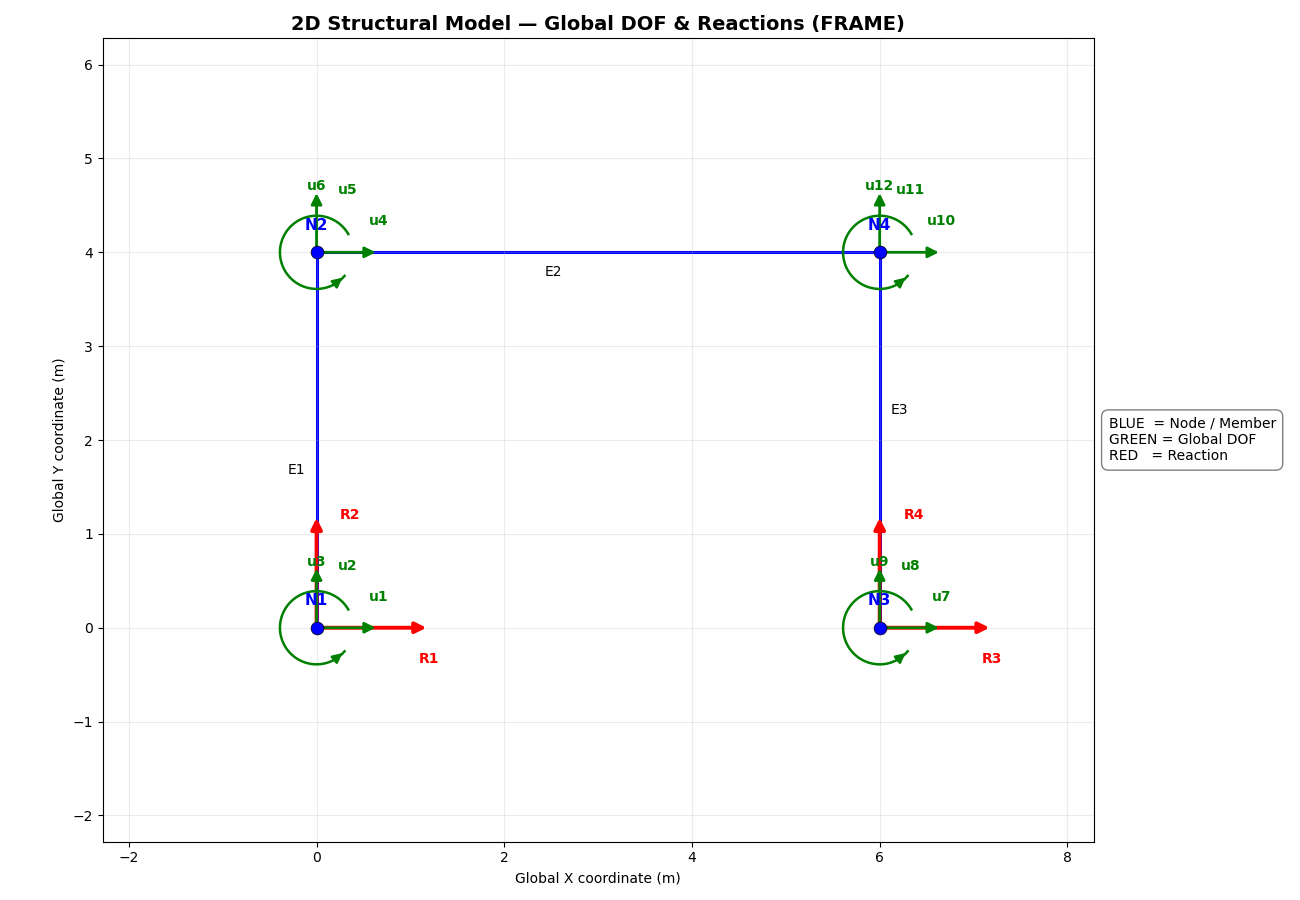


                 GLOBAL DOF NUMBERING
N1: u1 (X), u2 (Y), u3 (RZ)
N2: u4 (X), u5 (Y), u6 (RZ)
N3: u7 (X), u8 (Y), u9 (RZ)
N4: u10 (X), u11 (Y), u12 (RZ)

                 GLOBAL REACTION NUMBERING
R1 : N1 : X
R2 : N1 : Y
R3 : N3 : X
R4 : N3 : Y


In [68]:
import math


# ============================================================|
# CHECK REQUIRED VARIABLES
# ============================================================

if "nodes" not in globals():
    raise RuntimeError("nodes is not defined.")

if "elements" not in globals():
    raise RuntimeError("elements is not defined.")

if "supports" not in globals():
    raise RuntimeError(
        "supports is not defined. "
        "Run support assignment first."
    )


# ============================================================
# ELEMENT TYPE
# ============================================================

etype = str(
    globals().get("element_type", "FRAME")
).upper()

if etype == "TRUSS":
    N_DOF = 2
else:
    # FRAME and BEAM
    N_DOF = 3


# ============================================================
# DOF NAMES
# ============================================================

def dof_name(node, local_dof):

    # Global DOF number
    global_dof = (
        (node - 1) * N_DOF
        + local_dof
    )

    if N_DOF == 2:

        if local_dof == 1:
            direction = "X"
        else:
            direction = "Y"

    else:

        if local_dof == 1:
            direction = "X"

        elif local_dof == 2:
            direction = "Y"

        else:
            direction = "RZ"

    return f"u{global_dof}", direction


# ============================================================
# SUPPORT DATA
# ============================================================

def get_support_data(node):

    value = supports.get(
        node,
        "FREE"
    )

    # --------------------------------------------------------
    # If support is stored as dictionary
    # --------------------------------------------------------

    if isinstance(value, dict):

        # Backward compatibility with old support format
        support_type = str(
            value.get("type", "FREE")
        ).upper()

        angle = float(
            value.get("angle", 0.0)
        )

    # --------------------------------------------------------
    # If support is stored as string
    # --------------------------------------------------------

    else:

        support_type = str(
            value
        ).upper()

        # ----------------------------------------------------
        # NEW CELL 6 FORMAT
        #
        # Support type and angle are stored separately:
        #
        # supports[node] = "ROLLER"
        # support_angles[node] = theta
        # ----------------------------------------------------

        if "support_angles" in globals():

            angle = float(
                support_angles.get(
                    node,
                    0.0
                )
            )

        else:

            angle = 0.0

    return support_type, angle


# ============================================================
# DETERMINE RESTRAINED DOFS
# ============================================================

def restrained_dofs(
    support_type,
    angle=0
):

    support_type = support_type.upper()

    # --------------------------------------------------------
    # FREE
    # --------------------------------------------------------

    if support_type == "FREE":

        return []


    # --------------------------------------------------------
    # PIN
    # X + Y restrained
    # --------------------------------------------------------

    if support_type == "PIN":

        return [
            ("X", None),
            ("Y", None)
        ]


    # --------------------------------------------------------
    # FIXED
    # X + Y + ROTATION
    # --------------------------------------------------------

    if support_type == "FIXED":

        if N_DOF == 2:

            return [
                ("X", None),
                ("Y", None)
            ]

        return [
            ("X", None),
            ("Y", None),
            ("RZ", None)
        ]


    # --------------------------------------------------------
    # ROLLER
    #
    # Reaction is NORMAL to roller surface.
    #
    # If roller surface = angle from horizontal,
    # reaction direction = angle + 90 degrees.
    # --------------------------------------------------------

    if support_type == "ROLLER":

        reaction_angle = (
            float(angle) + 90.0
        )

        return [
            ("ROLLER", reaction_angle)
        ]


    return []


# ============================================================
# CREATE GLOBAL REACTION LIST
# ============================================================

reaction_data = []

reaction_counter = 1


for node in nodes:

    support_type, angle = get_support_data(
        node
    )

    restrained = restrained_dofs(
        support_type,
        angle
    )

    for item in restrained:

        direction = item[0]
        reaction_angle = item[1]

        reaction_data.append({

            "number":
                reaction_counter,

            "node":
                node,

            "direction":
                direction,

            "angle":
                reaction_angle,

            "support":
                support_type
        })

        reaction_counter += 1


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 9)
)


# ============================================================
# MODEL DIMENSIONS
# ============================================================

x_values = [
    float(p[0])
    for p in nodes.values()
]

y_values = [
    float(p[1])
    for p in nodes.values()
]

xmin = min(x_values)
xmax = max(x_values)

ymin = min(y_values)
ymax = max(y_values)

scale = max(
    xmax - xmin,
    ymax - ymin,
    1.0
)


# ============================================================
# VISUAL PARAMETERS
# ============================================================

NODE_SIZE = 85

DOF_LEN = 0.11 * scale

REACTION_LEN = 0.20 * scale

NODE_LABEL_OFFSET = 0.035 * scale


# ============================================================
# DRAW MEMBERS
# ============================================================

for eid, (ni, nj) in enumerate(
    elements,
    start=1
):

    xi, yi = nodes[ni]
    xj, yj = nodes[nj]

    # --------------------------------------------------------
    # MEMBER
    # --------------------------------------------------------

    ax.plot(
        [xi, xj],
        [yi, yj],
        color="blue",
        linewidth=2.2,
        zorder=1
    )

    # --------------------------------------------------------
    # MEMBER LABEL
    # Offset perpendicular to member
    # --------------------------------------------------------

    dx = xj - xi
    dy = yj - yi

    L = math.sqrt(
        dx**2 + dy**2
    )

    if L > 0:

        # Use 42% instead of exact midpoint
        t = 0.42

        xm = xi + t * dx
        ym = yi + t * dy

        nx = -dy / L
        ny = dx / L

        offset = (
            0.035 * scale
        )

        # Alternate side for crossing members
        if eid % 2 == 0:
            offset *= -1

        xm += nx * offset
        ym += ny * offset

        ax.text(
            xm,
            ym,
            f"E{eid}",
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                pad=2
            ),
            zorder=10
        )


# ============================================================
# DRAW NODES
# ============================================================

for node, (x, y) in nodes.items():

    ax.scatter(
        x,
        y,
        s=NODE_SIZE,
        color="blue",
        edgecolors="black",
        linewidths=0.5,
        zorder=30
    )

    ax.text(
        x,
        y + NODE_LABEL_OFFSET,
        f"N{node}",
        fontsize=11,
        fontweight="bold",
        color="blue",
        ha="center",
        va="bottom",
        zorder=40
    )


# ============================================================
# ARROW FUNCTION
# ============================================================

def arrow(
    x1,
    y1,
    x2,
    y2,
    label,
    color,
    dx_text=0,
    dy_text=0,
    zorder=20,
    linewidth=2.2
):

    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-|>",
            color=color,
            linewidth=linewidth,
            mutation_scale=16
        ),
        zorder=zorder
    )

    ax.text(
        x2 + dx_text,
        y2 + dy_text,
        label,
        fontsize=10,
        fontweight="bold",
        color=color,
        ha="center",
        va="center",
        zorder=zorder + 1
    )


# ============================================================
# REACTION ARROWS
# ============================================================

# Reaction numbering is GLOBAL and UNIQUE.
#
# Example:
#
# N1 PIN    -> R1 R2
# N2 ROLLER -> R3
# N3 FIXED  -> R4 R5 R6
#
# ============================================================

for reaction in reaction_data:

    R = reaction["number"]

    node = reaction["node"]

    direction = reaction["direction"]

    angle = reaction["angle"]

    x, y = nodes[node]


    # ========================================================
    # X REACTION
    # ========================================================

    if direction == "X":

        arrow(
            x,
            y,
            x + REACTION_LEN,
            y,
            f"R{R}",
            "red",

            dy_text=-0.055 * scale,

            zorder=12,

            linewidth=2.8
        )


    # ========================================================
    # Y REACTION
    # ========================================================

    elif direction == "Y":

        arrow(
            x,
            y,
            x,
            y + REACTION_LEN,
            f"R{R}",
            "red",

            dx_text=0.06 * scale,

            zorder=12,

            linewidth=2.8
        )


    # ========================================================
    # RZ MOMENT REACTION
    # ========================================================

    elif direction == "RZ":

        radius = 0.12 * scale

        theta = np.linspace(
            np.radians(40),
            np.radians(320),
            80
        )

        arc_x = (
            x
            + radius * np.cos(theta)
        )

        arc_y = (
            y
            + radius * np.sin(theta)
        )

        ax.plot(
            arc_x,
            arc_y,
            color="red",
            linewidth=2.8,
            zorder=12
        )

        ax.annotate(
            "",
            xy=(
                arc_x[-1],
                arc_y[-1]
            ),
            xytext=(
                arc_x[-7],
                arc_y[-7]
            ),
            arrowprops=dict(
                arrowstyle="-|>",
                color="red",
                linewidth=2.8,
                mutation_scale=16
            ),
            zorder=13
        )

        ax.text(
            x - radius * 1.25,
            y + radius * 0.65,
            f"R{R}",
            fontsize=10,
            fontweight="bold",
            color="red",
            ha="center",
            zorder=14
        )


    # ========================================================
    # ROLLER REACTION
    # ========================================================

    elif direction == "ROLLER":

        # ----------------------------------------------------
        # angle is already reaction angle
        # ----------------------------------------------------

        theta = math.radians(
            angle
        )

        dx = (
            REACTION_LEN
            * math.cos(theta)
        )

        dy = (
            REACTION_LEN
            * math.sin(theta)
        )

        # ----------------------------------------------------
        # Draw reaction
        # ----------------------------------------------------

        arrow(
            x,
            y,
            x + dx,
            y + dy,
            f"R{R}",
            "red",

            dx_text=(
                0.045 * scale
                * np.sign(dx if dx != 0 else 1)
            ),

            dy_text=(
                0.045 * scale
                * np.sign(dy if dy != 0 else 1)
            ),

            zorder=12,

            linewidth=2.8
        )


# ============================================================
# GLOBAL DOF ARROWS
# ============================================================

# IMPORTANT:
#
# DOFs are now numbered globally.
#
# TRUSS:
#
# N1 -> u1 u2
# N2 -> u3 u4
# N3 -> u5 u6
# N4 -> u7 u8
#
# FRAME:
#
# N1 -> u1 u2 u3
# N2 -> u4 u5 u6
# N3 -> u7 u8 u9
# N4 -> u10 u11 u12
#
# ============================================================

for node, (x, y) in nodes.items():

    # ========================================================
    # uX
    # ========================================================

    label_x, _ = dof_name(
        node,
        1
    )

    arrow(
        x,
        y,
        x + DOF_LEN,
        y,
        label_x,
        "green",

        dy_text=0.055 * scale,

        zorder=22,

        linewidth=2.0
    )


    # ========================================================
    # uY
    # ========================================================

    label_y, _ = dof_name(
        node,
        2
    )

    arrow(
        x,
        y,
        x,
        y + DOF_LEN,
        label_y,
        "green",

        dx_text=0.055 * scale,

        zorder=22,

        linewidth=2.0
    )


    # ========================================================
    # ROTATIONAL DOF
    # FRAME / BEAM ONLY
    # ========================================================

    if N_DOF == 3:

        label_r, _ = dof_name(
            node,
            3
        )

        radius = (
            0.065 * scale
        )

        theta = np.linspace(
            np.radians(30),
            np.radians(320),
            70
        )

        arc_x = (
            x
            + radius * np.cos(theta)
        )

        arc_y = (
            y
            + radius * np.sin(theta)
        )

        ax.plot(
            arc_x,
            arc_y,
            color="green",
            linewidth=1.8,
            zorder=22
        )

        ax.annotate(
            "",
            xy=(
                arc_x[-1],
                arc_y[-1]
            ),
            xytext=(
                arc_x[-6],
                arc_y[-6]
            ),
            arrowprops=dict(
                arrowstyle="-|>",
                color="green",
                linewidth=1.8,
                mutation_scale=14
            ),
            zorder=23
        )

        ax.text(
            x,
            y + radius + 0.045 * scale,
            label_r,
            fontsize=10,
            fontweight="bold",
            color="green",
            ha="center",
            zorder=25
        )


# ============================================================
# LEGEND
# ============================================================

ax.text(
    1.015,
    0.50,

    "BLUE  = Node / Member\n"
    "GREEN = Global DOF\n"
    "RED   = Reaction",

    transform=ax.transAxes,

    fontsize=10,

    verticalalignment="center",

    bbox=dict(
        facecolor="white",
        edgecolor="gray",
        boxstyle="round,pad=0.5"
    )
)


# ============================================================
# AXIS LIMITS
# ============================================================

margin = 0.38 * scale

ax.set_xlim(
    xmin - margin,
    xmax + margin
)

ax.set_ylim(
    ymin - margin,
    ymax + margin
)

ax.set_aspect(
    "equal",
    adjustable="box"
)

ax.grid(
    True,
    alpha=0.25
)

ax.set_xlabel(
    "Global X coordinate (m)"
)

ax.set_ylabel(
    "Global Y coordinate (m)"
)

ax.set_title(
    f"2D Structural Model — Global DOF & Reactions ({etype})",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()


# ============================================================
# PRINT GLOBAL DOF TABLE
# ============================================================

print()
print("=" * 65)
print("                 GLOBAL DOF NUMBERING")
print("=" * 65)

for node in nodes:

    labels = []

    for local in range(
        1,
        N_DOF + 1
    ):

        label, direction = dof_name(
            node,
            local
        )

        labels.append(
            f"{label} ({direction})"
        )

    print(
        f"N{node}: "
        + ", ".join(labels)
    )


# ============================================================
# PRINT GLOBAL REACTION TABLE
# ============================================================

print()
print("=" * 65)
print("                 GLOBAL REACTION NUMBERING")
print("=" * 65)

if len(reaction_data) == 0:

    print("No reactions.")

else:

    for r in reaction_data:

        if r["direction"] == "ROLLER":

            print(
                f"R{r['number']} : "
                f"N{r['node']} : "
                f"ROLLER NORMAL "
                f"{r['angle']:.2f}°"
            )

        else:

            print(
                f"R{r['number']} : "
                f"N{r['node']} : "
                f"{r['direction']}"
            )

print("=" * 65)

#  LOAD ASSIGNMENT GUI

In [69]:
# ============================================================
# CELL 7 : OPTIMIZED LOAD ASSIGNMENT GUI
# ============================================================
#
# REQUIREMENTS:
#   nodes    -> existing dictionary
#               example: {1:(0,0), 2:(5,0), ...}
#
#   elements -> existing list
#               example: [(1,2), (2,3), ...]
#
#   element_type -> "TRUSS", "BEAM" or "FRAME"
#
# Units:
#   Point load       = kN
#   Distributed load = kN/m
#   distance         = local distance from I-node in metres
#
# ============================================================

import sys
import math
import pyqtgraph as pg
from PyQt5 import QtWidgets, QtCore, QtGui


# ============================================================
# CHECK INPUT DATA
# ============================================================

if "nodes" not in globals():
    raise RuntimeError("nodes dictionary was not found.")

if "elements" not in globals():
    raise RuntimeError("elements list was not found.")

if "element_type" not in globals():
    element_type = "FRAME"


# ============================================================
# CLOSE PREVIOUS LOAD WINDOW
# ============================================================

try:
    if "load_window" in globals() and load_window is not None:
        load_window.close()
        load_window.deleteLater()
except:
    pass


# ============================================================
# GLOBAL LOAD STORAGE
# ============================================================

# Each load is stored as a dictionary.
#
# Example POINT:
# {
#   "id": 1,
#   "target": "NODE",
#   "node": 4,
#   "type": "POINT",
#   "magnitude": 10,
#   "angle": 90
# }
#
# Example UDL:
# {
#   "id": 2,
#   "target": "MEMBER",
#   "element": 3,
#   "type": "UDL",
#   "magnitude": 10,
#   "angle": 90,
#   "start": 0,
#   "end": 5   # actual distance in metres
# }
#
# Example variable:
# {
#   "id": 3,
#   "target": "MEMBER",
#   "type": "VARIABLE",
#   "equation": "10*x",
#   ...
# }

applied_loads = []
next_load_id = 1

# ============================================================
# INTERNAL HINGE STORAGE
# ============================================================
#
# Each internal hinge is stored as:
#
# {
#     "id": 1,
#     "element": 3,
#     "position": 2.50
# }
#
# position = actual distance from the I-node of the member.
#
# An internal hinge is a MEMBER RELEASE, not an external
# support, so it is stored separately from "supports".
#
# ============================================================

internal_hinges = []
next_hinge_id = 1


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def node_xy(node):
    return np.array(nodes[node], dtype=float)


def member_xy(element_id):
    ni, nj = elements[element_id - 1]

    pi = node_xy(ni)
    pj = node_xy(nj)

    return ni, nj, pi, pj


def distance_point_to_segment(p, a, b):

    ab = b - a
    ab2 = np.dot(ab, ab)

    if ab2 == 0:
        return np.linalg.norm(p - a)

    t = np.dot(p - a, ab) / ab2
    t = max(0.0, min(1.0, t))

    closest = a + t * ab

    return np.linalg.norm(p - closest)


def nearest_node(point):

    best_node = None
    best_distance = float("inf")

    for n, xy in nodes.items():

        d = np.linalg.norm(
            np.array(xy, dtype=float) - point
        )

        if d < best_distance:
            best_distance = d
            best_node = n

    return best_node, best_distance


def nearest_member(point):

    best_element = None
    best_distance = float("inf")

    for eid, (ni, nj) in enumerate(elements, start=1):

        a = node_xy(ni)
        b = node_xy(nj)

        d = distance_point_to_segment(
            point, a, b
        )

        if d < best_distance:
            best_distance = d
            best_element = eid

    return best_element, best_distance


# ============================================================
# SAFE EQUATION EVALUATOR
# ============================================================

SAFE_FUNCTIONS = {
    "sin": np.sin,
    "cos": np.cos,
    "tan": np.tan,
    "sqrt": np.sqrt,
    "abs": np.abs,
    "exp": np.exp,
    "log": np.log,
    "pi": np.pi,
    "e": np.e
}


def evaluate_equation(expression, x, L):

    expression = expression.strip()

    if not expression:
        raise ValueError("Enter a load equation.")

    # Allow the user to write x.
    # L is also available if required.
    allowed = {
        "x": x,
        "L": L,
        **SAFE_FUNCTIONS
    }

    try:

        value = eval(
            expression,
            {
                "__builtins__": {}
            },
            allowed
        )

        value = float(value)

        if not np.isfinite(value):
            raise ValueError

        return value

    except Exception:

        raise ValueError(
            "Invalid equation.\n\n"
            "Examples:\n"
            "10\n"
            "10*x\n"
            "20*(1-x/L)\n"
            "10*sin(pi*x/L)"
        )


# ============================================================
# MAIN WINDOW
# ============================================================

class LoadAssignmentWindow(QtWidgets.QMainWindow):

    def __init__(self):

        super().__init__()

        self.setWindowTitle(
            "2D Structural Model - Load Assignment"
        )

        self.resize(1250, 800)

        self.selected_node = None
        self.selected_element = None

        self.graphics = []

        self.build_ui()

        self.draw_structure()


    # ========================================================
    # USER INTERFACE
    # ========================================================

    def build_ui(self):

        central = QtWidgets.QWidget()
        self.setCentralWidget(central)

        main_layout = QtWidgets.QHBoxLayout(
            central
        )

        # ----------------------------------------------------
        # GRAPH
        # ----------------------------------------------------

        self.plot = pg.PlotWidget()

        self.plot.setBackground("w")

        self.plot.showGrid(
            x=True,
            y=True,
            alpha=0.18
        )

        self.plot.setLabel(
            "bottom",
            "X coordinate (m)"
        )

        self.plot.setLabel(
            "left",
            "Y coordinate (m)"
        )

        self.plot.setTitle(
            "2D Structural Model - Load Assignment"
        )

        self.plot.setMouseEnabled(
            x=True,
            y=True
        )

        main_layout.addWidget(
            self.plot,
            stretch=5
        )


        # ----------------------------------------------------
        # RIGHT PANEL
        # ----------------------------------------------------

        panel = QtWidgets.QWidget()

        panel.setMinimumWidth(360)
        panel.setMaximumWidth(400)

        panel_layout = QtWidgets.QVBoxLayout(
            panel
        )

        main_layout.addWidget(
            panel,
            stretch=1
        )


        # ----------------------------------------------------
        # SELECTION
        # ----------------------------------------------------

        panel_layout.addWidget(
            QtWidgets.QLabel(
                "<b>SELECTION</b>"
            )
        )

        self.selection_label = QtWidgets.QLabel(
            "No node/member selected"
        )

        self.selection_label.setStyleSheet(
            """
            QLabel {
                border: 1px solid #aaaaaa;
                padding: 10px;
                background: #f7f7f7;
            }
            """
        )

        panel_layout.addWidget(
            self.selection_label
        )


        # ----------------------------------------------------
        # LOAD TARGET
        # ----------------------------------------------------

        panel_layout.addWidget(
            QtWidgets.QLabel(
                "Load target:"
            )
        )

        self.target_combo = QtWidgets.QComboBox()

        self.target_combo.addItems([
            "NODE",
            "MEMBER"
        ])

        self.target_combo.currentTextChanged.connect(
            self.target_changed
        )

        panel_layout.addWidget(
            self.target_combo
        )


        # ----------------------------------------------------
        # LOAD TYPE
        # ----------------------------------------------------

        panel_layout.addWidget(
            QtWidgets.QLabel(
                "Load type:"
            )
        )

        self.load_type_combo = QtWidgets.QComboBox()

        self.load_type_combo.addItems([
            "POINT LOAD",
            "DISTRIBUTED LOAD"
        ])

        self.load_type_combo.currentTextChanged.connect(
            self.load_type_changed
        )

        panel_layout.addWidget(
            self.load_type_combo
        )


        # ----------------------------------------------------
        # DISTRIBUTED LOAD TYPE
        # ----------------------------------------------------

        self.dist_label = QtWidgets.QLabel(
            "Distributed load type:"
        )

        panel_layout.addWidget(
            self.dist_label
        )

        self.dist_combo = QtWidgets.QComboBox()

        self.dist_combo.addItems([
            "UDL",
            "VARIABLE - EQUATION"
        ])

        self.dist_combo.currentTextChanged.connect(
            self.dist_type_changed
        )

        panel_layout.addWidget(
            self.dist_combo
        )


        # ----------------------------------------------------
        # MAGNITUDE
        # ----------------------------------------------------

        self.magnitude_label = QtWidgets.QLabel(
            "Magnitude:"
        )

        panel_layout.addWidget(
            self.magnitude_label
        )

        self.magnitude_edit = QtWidgets.QLineEdit()

        self.magnitude_edit.setPlaceholderText(
            "Point: 10 kN   |   UDL: 10 kN/m"
        )

        panel_layout.addWidget(
            self.magnitude_edit
        )


        # ----------------------------------------------------
        # EQUATION
        # ----------------------------------------------------

        self.equation_label = QtWidgets.QLabel(
            "Variable load q(x) [kN/m]:"
        )

        panel_layout.addWidget(
            self.equation_label
        )

        self.equation_edit = QtWidgets.QLineEdit()

        self.equation_edit.setPlaceholderText(
            "Example: 10*x or 20*(1-x/L)"
        )

        panel_layout.addWidget(
            self.equation_edit
        )


        # ----------------------------------------------------
        # ANGLE
        # ----------------------------------------------------

        self.angle_label = QtWidgets.QLabel(
            "Angle (° from global +X):"
        )

        panel_layout.addWidget(
            self.angle_label
        )

        self.angle_edit = QtWidgets.QLineEdit(
            "90"
        )

        panel_layout.addWidget(
            self.angle_edit
        )


        # ----------------------------------------------------
        # START / DISTANCE FROM I-NODE
        # ----------------------------------------------------

        self.start_label = QtWidgets.QLabel(
            "Distance from I-node (m):"
        )

        panel_layout.addWidget(
            self.start_label
        )

        self.start_edit = QtWidgets.QLineEdit(
            "0"
        )

        panel_layout.addWidget(
            self.start_edit
        )


        # ----------------------------------------------------
        # END DISTANCE FROM I-NODE
        # ----------------------------------------------------

        self.end_label = QtWidgets.QLabel(
            "End distance from I-node (m):"
        )

        panel_layout.addWidget(
            self.end_label
        )

        self.end_edit = QtWidgets.QLineEdit(
            "1"
        )

        panel_layout.addWidget(
            self.end_edit
        )


        # ----------------------------------------------------
        # APPLY
        # ----------------------------------------------------

        self.apply_button = QtWidgets.QPushButton(
            "APPLY LOAD"
        )

        self.apply_button.setMinimumHeight(
            40
        )

        self.apply_button.clicked.connect(
            self.apply_load
        )

        panel_layout.addWidget(
            self.apply_button
        )


        # ----------------------------------------------------
        # CLEAR SELECTION
        # ----------------------------------------------------

        self.clear_button = QtWidgets.QPushButton(
            "CLEAR SELECTION"
        )

        self.clear_button.clicked.connect(
            self.clear_selection
        )

        panel_layout.addWidget(
            self.clear_button
        )


        # ----------------------------------------------------
        # INTERNAL HINGE
        # ----------------------------------------------------

        self.hinge_button = QtWidgets.QPushButton(
            "ADD INTERNAL HINGE"
        )

        self.hinge_button.setMinimumHeight(
            40
        )

        self.hinge_button.setStyleSheet(
            """
            QPushButton {
                font-weight: bold;
                padding: 6px;
            }
            """
        )

        self.hinge_button.clicked.connect(
            self.add_internal_hinge
        )

        panel_layout.addWidget(
            self.hinge_button
        )


        # ----------------------------------------------------
        # SAVED INTERNAL HINGES
        # ----------------------------------------------------

        panel_layout.addWidget(
            QtWidgets.QLabel(
                "<b>INTERNAL HINGES</b>"
            )
        )

        self.hinge_table = QtWidgets.QTableWidget()

        self.hinge_table.setColumnCount(4)

        self.hinge_table.setHorizontalHeaderLabels([
            "ID",
            "MEMBER",
            "DISTANCE FROM I",
            "DELETE"
        ])

        self.hinge_table.setEditTriggers(
            QtWidgets.QAbstractItemView.NoEditTriggers
        )

        self.hinge_table.setSelectionBehavior(
            QtWidgets.QAbstractItemView.SelectRows
        )

        self.hinge_table.setColumnWidth(
            0, 45
        )

        self.hinge_table.setColumnWidth(
            1, 80
        )

        self.hinge_table.setColumnWidth(
            2, 125
        )

        self.hinge_table.setColumnWidth(
            3, 70
        )

        panel_layout.addWidget(
            self.hinge_table
        )


        # ----------------------------------------------------
        # SAVED LOADS
        # ----------------------------------------------------

        panel_layout.addWidget(
            QtWidgets.QLabel(
                "<b>SAVED LOADS</b>"
            )
        )

        self.load_table = QtWidgets.QTableWidget()

        self.load_table.setColumnCount(5)

        self.load_table.setHorizontalHeaderLabels([
            "ID",
            "TARGET",
            "TYPE",
            "DETAILS",
            "DELETE"
        ])

        self.load_table.setEditTriggers(
            QtWidgets.QAbstractItemView.NoEditTriggers
        )

        self.load_table.setSelectionBehavior(
            QtWidgets.QAbstractItemView.SelectRows
        )

        self.load_table.horizontalHeader().setStretchLastSection(
            False
        )

        self.load_table.setColumnWidth(
            0, 40
        )

        self.load_table.setColumnWidth(
            1, 80
        )

        self.load_table.setColumnWidth(
            2, 90
        )

        self.load_table.setColumnWidth(
            3, 210
        )

        self.load_table.setColumnWidth(
            4, 70
        )

        panel_layout.addWidget(
            self.load_table,
            stretch=1
        )


        # ----------------------------------------------------
        # STATUS
        # ----------------------------------------------------

        self.status_label = QtWidgets.QLabel(
            ""
        )

        self.status_label.setWordWrap(
            True
        )

        panel_layout.addWidget(
            self.status_label
        )


        # ----------------------------------------------------
        # INITIAL UI STATE
        # ----------------------------------------------------

        self.target_changed(
            self.target_combo.currentText()
        )

        self.refresh_hinge_table()


    # ========================================================
    # TARGET CHANGED
    # ========================================================

    def target_changed(self, target):

        if target == "NODE":

            self.load_type_combo.clear()

            self.load_type_combo.addItem(
                "POINT LOAD"
            )

            self.dist_label.hide()
            self.dist_combo.hide()

            self.equation_label.hide()
            self.equation_edit.hide()

            self.start_label.hide()
            self.start_edit.hide()

            self.end_label.hide()
            self.end_edit.hide()

            self.magnitude_label.setText(
                "Magnitude (kN):"
            )

            self.magnitude_edit.setPlaceholderText(
                "Example: 10"
            )

        else:

            self.load_type_combo.clear()

            self.load_type_combo.addItems([
                "POINT LOAD",
                "DISTRIBUTED LOAD"
            ])

            self.dist_label.show()
            self.dist_combo.show()

            self.magnitude_label.setText(
                "Magnitude (kN):"
            )

            self.load_type_changed(
                self.load_type_combo.currentText()
            )


    # ========================================================
    # LOAD TYPE CHANGED
    # ========================================================

    def load_type_changed(self, load_type):

        target = self.target_combo.currentText()

        if target == "NODE":

            self.dist_label.hide()
            self.dist_combo.hide()

            self.equation_label.hide()
            self.equation_edit.hide()

            self.start_label.hide()
            self.start_edit.hide()

            self.end_label.hide()
            self.end_edit.hide()

            self.magnitude_label.setText(
                "Magnitude (kN):"
            )

            self.magnitude_edit.show()
            self.magnitude_label.show()

            self.angle_label.show()
            self.angle_edit.show()

            return


        if load_type == "POINT LOAD":

            self.dist_label.hide()
            self.dist_combo.hide()

            self.equation_label.hide()
            self.equation_edit.hide()

            # Member point load is placed at an actual distance
            # measured from the I-node along the member.
            self.start_label.setText(
                "Distance from I-node (m):"
            )
            self.start_label.show()
            self.start_edit.show()

            self.end_label.hide()
            self.end_edit.hide()

            self.magnitude_label.setText(
                "Magnitude (kN):"
            )

            self.magnitude_edit.show()
            self.magnitude_label.show()

            self.angle_label.show()

        else:

            self.dist_label.show()
            self.dist_combo.show()

            self.start_label.setText(
                "Start distance from I-node (m):"
            )
            self.start_label.show()
            self.start_edit.show()

            self.end_label.setText(
                "End distance from I-node (m):"
            )
            self.end_label.show()
            self.end_edit.show()

            self.magnitude_label.show()

            self.angle_label.show()

            self.dist_type_changed(
                self.dist_combo.currentText()
            )


    # ========================================================
    # DISTRIBUTED TYPE CHANGED
    # ========================================================

    def dist_type_changed(self, dist_type):

        if self.target_combo.currentText() != "MEMBER":
            return

        if self.load_type_combo.currentText() != "DISTRIBUTED LOAD":
            return

        if dist_type == "UDL":

            self.magnitude_label.setText(
                "UDL magnitude w (kN/m):"
            )

            self.magnitude_edit.show()
            self.magnitude_label.show()

            self.equation_label.hide()
            self.equation_edit.hide()

        else:

            # IMPORTANT:
            # Variable load has NO magnitude field.

            self.magnitude_label.hide()
            self.magnitude_edit.hide()

            self.equation_label.setText(
                "Variable load q(x) (kN/m):"
            )

            self.equation_label.show()
            self.equation_edit.show()


    # ========================================================
    # MOUSE SELECTION
    # ========================================================

    def mouse_clicked(self, event):

        if event.button() != QtCore.Qt.LeftButton:
            return

        mouse_point = self.plot.plotItem.vb.mapSceneToView(
            event.scenePos()
        )

        p = np.array([
            mouse_point.x(),
            mouse_point.y()
        ])

        target = self.target_combo.currentText()


        # ----------------------------------------------------
        # NODE TARGET
        # ----------------------------------------------------

        if target == "NODE":

            node, distance = nearest_node(p)

            # Selection tolerance
            x_range, y_range = self.get_plot_ranges()

            tolerance = 0.06 * max(
                x_range,
                y_range
            )

            if distance <= tolerance:

                self.selected_node = node
                self.selected_element = None

                self.selection_label.setText(
                    f"Selected Node: N{node}"
                )

                self.status_label.setText(
                    f"Node N{node} selected."
                )

                self.draw_structure()

            return


        # ----------------------------------------------------
        # MEMBER TARGET
        # ----------------------------------------------------

        element, distance = nearest_member(p)

        x_range, y_range = self.get_plot_ranges()

        tolerance = 0.04 * max(
            x_range,
            y_range
        )

        if distance <= tolerance:

            self.selected_element = element
            self.selected_node = None

            ni, nj, pi, pj = member_xy(
                element
            )

            # Set member distance limits using the actual member length.
            member_length = np.linalg.norm(pj - pi)
            self.start_edit.setText("0")
            self.end_edit.setText(f"{member_length:g}")

            # For a member point load, only the distance from I-node is used.
            if self.load_type_combo.currentText() == "POINT LOAD":
                self.start_edit.setText("0")

            self.selection_label.setText(
                f"Selected Member: E{element}\n"
                f"I-node: N{ni}    J-node: N{nj}"
            )

            self.status_label.setText(
                f"Member E{element} selected."
            )

            self.draw_structure()


    # ========================================================
    # PLOT RANGE
    # ========================================================

    def get_plot_ranges(self):

        xs = [
            nodes[n][0]
            for n in nodes
        ]

        ys = [
            nodes[n][1]
            for n in nodes
        ]

        return (
            max(xs) - min(xs),
            max(ys) - min(ys)
        )


    # ========================================================
    # CLEAR SELECTION
    # ========================================================

    def clear_selection(self):

        self.selected_node = None
        self.selected_element = None

        self.selection_label.setText(
            "No node/member selected"
        )

        self.status_label.setText(
            ""
        )

        self.draw_structure()


    # ========================================================
    # APPLY LOAD
    # ========================================================

    def apply_load(self):

        global next_load_id

        target = self.target_combo.currentText()
        load_type = self.load_type_combo.currentText()


        # ----------------------------------------------------
        # NODE POINT LOAD
        # ----------------------------------------------------

        if target == "NODE":

            if self.selected_node is None:

                QtWidgets.QMessageBox.warning(
                    self,
                    "No node selected",
                    "Click a node first."
                )

                return

            try:

                magnitude = float(
                    self.magnitude_edit.text()
                )

                angle = float(
                    self.angle_edit.text()
                )

            except:

                QtWidgets.QMessageBox.warning(
                    self,
                    "Invalid input",
                    "Enter valid magnitude and angle."
                )

                return


            load = {
                "id": next_load_id,
                "target": "NODE",
                "node": self.selected_node,
                "type": "POINT",
                "magnitude": magnitude,
                "angle": angle
            }


        # ----------------------------------------------------
        # MEMBER
        # ----------------------------------------------------

        else:

            if self.selected_element is None:

                QtWidgets.QMessageBox.warning(
                    self,
                    "No member selected",
                    "Click a member first."
                )

                return


            # ------------------------------------------------
            # MEMBER POINT LOAD
            # ------------------------------------------------

            if load_type == "POINT LOAD":

                try:

                    magnitude = float(
                        self.magnitude_edit.text()
                    )

                    angle = float(
                        self.angle_edit.text()
                    )

                    position = float(
                        self.start_edit.text()
                    )

                except:

                    QtWidgets.QMessageBox.warning(
                        self,
                        "Invalid input",
                        "Enter valid load data."
                    )

                    return


                ni, nj, pi, pj = member_xy(
                    self.selected_element
                )

                L = np.linalg.norm(
                    pj - pi
                )

                if not 0 <= position <= L:

                    QtWidgets.QMessageBox.warning(
                        self,
                        "Invalid position",
                        f"Distance must be between 0 and {L:.3f} m from the I-node."
                    )

                    return


                load = {
                    "id": next_load_id,
                    "target": "MEMBER",
                    "element": self.selected_element,
                    "type": "POINT",
                    "magnitude": magnitude,
                    "angle": angle,
                    "position": position
                }


            # ------------------------------------------------
            # DISTRIBUTED LOAD
            # ------------------------------------------------

            else:

                try:

                    angle = float(
                        self.angle_edit.text()
                    )

                    start = float(
                        self.start_edit.text()
                    )

                    end = float(
                        self.end_edit.text()
                    )

                except:

                    QtWidgets.QMessageBox.warning(
                        self,
                        "Invalid input",
                        "Enter valid angle and positions."
                    )

                    return


                ni, nj, pi, pj = member_xy(
                    self.selected_element
                )

                L = np.linalg.norm(
                    pj - pi
                )

                if not (
                    0 <= start < end <= L
                ):

                    QtWidgets.QMessageBox.warning(
                        self,
                        "Invalid range",
                        f"Use 0 <= start < end <= {L:.3f} m from the I-node."
                    )

                    return


                # --------------------------------------------
                # UDL
                # --------------------------------------------

                if self.dist_combo.currentText() == "UDL":

                    try:

                        magnitude = float(
                            self.magnitude_edit.text()
                        )

                    except:

                        QtWidgets.QMessageBox.warning(
                            self,
                            "Invalid UDL",
                            "Enter UDL in kN/m."
                        )

                        return


                    load = {
                        "id": next_load_id,
                        "target": "MEMBER",
                        "element": self.selected_element,
                        "type": "UDL",
                        "magnitude": magnitude,
                        "angle": angle,
                        "start": start,
                        "end": end
                    }


                # --------------------------------------------
                # VARIABLE EQUATION
                # --------------------------------------------

                else:

                    equation = (
                        self.equation_edit
                        .text()
                        .strip()
                    )

                    if not equation:

                        QtWidgets.QMessageBox.warning(
                            self,
                            "Missing equation",
                            "Enter q(x)."
                        )

                        return


                    # Test equation before saving
                    ni, nj, pi, pj = member_xy(
                        self.selected_element
                    )

                    L = np.linalg.norm(
                        pj - pi
                    )

                    try:

                        test_values = [
                            evaluate_equation(
                                equation,
                                start,
                                L
                            ),
                            evaluate_equation(
                                equation,
                                end,
                                L
                            )
                        ]

                    except ValueError as e:

                        QtWidgets.QMessageBox.warning(
                            self,
                            "Invalid equation",
                            str(e)
                        )

                        return


                    load = {
                        "id": next_load_id,
                        "target": "MEMBER",
                        "element": self.selected_element,
                        "type": "VARIABLE",
                        "equation": equation,
                        "angle": angle,
                        "start": start,
                        "end": end
                    }


        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        applied_loads.append(
            load
        )

        next_load_id += 1

        self.refresh_table()

        self.draw_structure()

        self.status_label.setText(
            f"Load L{load['id']} saved."
        )


    # ========================================================
    # ADD INTERNAL HINGE
    # ========================================================

    def add_internal_hinge(self):

        global next_hinge_id

        if self.selected_element is None:

            QtWidgets.QMessageBox.warning(
                self,
                "No member selected",
                "Select a member first, then enter the "
                "distance from its I-node."
            )

            return

        try:

            position = float(
                self.start_edit.text()
            )

        except:

            QtWidgets.QMessageBox.warning(
                self,
                "Invalid position",
                "Enter a valid distance from the I-node."
            )

            return

        ni, nj, pi, pj = member_xy(
            self.selected_element
        )

        L = np.linalg.norm(
            pj - pi
        )

        if not (
            0.0 < position < L
        ):

            QtWidgets.QMessageBox.warning(
                self,
                "Invalid hinge position",
                f"Internal hinge distance must be strictly "
                f"between 0 and {L:.3f} m from the I-node."
            )

            return

        tolerance = 1e-9

        for hinge in internal_hinges:

            if (
                hinge["element"] == self.selected_element
                and
                abs(
                    hinge["position"] - position
                ) <= tolerance
            ):

                QtWidgets.QMessageBox.warning(
                    self,
                    "Duplicate hinge",
                    "An internal hinge already exists at "
                    "this position."
                )

                return

        hinge = {
            "id": next_hinge_id,
            "element": self.selected_element,
            "position": position
        }

        internal_hinges.append(
            hinge
        )

        next_hinge_id += 1

        self.refresh_hinge_table()

        self.draw_structure()

        self.status_label.setText(
            f"Internal hinge H{hinge['id']} added on "
            f"E{self.selected_element} at "
            f"{position:.3f} m from I."
        )


    # ========================================================
    # DELETE INTERNAL HINGE
    # ========================================================

    def delete_internal_hinge(self, hinge_id):

        global internal_hinges

        internal_hinges = [
            hinge
            for hinge in internal_hinges
            if hinge["id"] != hinge_id
        ]

        self.refresh_hinge_table()

        self.draw_structure()

        self.status_label.setText(
            f"Internal hinge H{hinge_id} deleted."
        )


    # ========================================================
    # REFRESH INTERNAL HINGE TABLE
    # ========================================================

    def refresh_hinge_table(self):

        self.hinge_table.setRowCount(
            0
        )

        for hinge in internal_hinges:

            row = self.hinge_table.rowCount()

            self.hinge_table.insertRow(
                row
            )

            hinge_id = hinge["id"]

            element = hinge["element"]

            position = hinge["position"]

            self.hinge_table.setItem(
                row,
                0,
                QtWidgets.QTableWidgetItem(
                    f"H{hinge_id}"
                )
            )

            self.hinge_table.setItem(
                row,
                1,
                QtWidgets.QTableWidgetItem(
                    f"E{element}"
                )
            )

            self.hinge_table.setItem(
                row,
                2,
                QtWidgets.QTableWidgetItem(
                    f"{position:.3f} m"
                )
            )

            button = QtWidgets.QPushButton(
                "DELETE"
            )

            button.clicked.connect(
                lambda checked=False,
                       hid=hinge_id:
                    self.delete_internal_hinge(hid)
            )

            self.hinge_table.setCellWidget(
                row,
                3,
                button
            )


    # ========================================================
    # DELETE LOAD
    # ========================================================

    def delete_load(self, load_id):

        global applied_loads

        applied_loads = [
            load
            for load in applied_loads
            if load["id"] != load_id
        ]

        self.refresh_table()

        self.draw_structure()

        self.status_label.setText(
            f"Load L{load_id} deleted."
        )


    # ========================================================
    # REFRESH LOAD TABLE
    # ========================================================

    def refresh_table(self):

        self.load_table.setRowCount(
            0
        )

        for load in applied_loads:

            row = self.load_table.rowCount()

            self.load_table.insertRow(
                row
            )

            load_id = load["id"]

            self.load_table.setItem(
                row,
                0,
                QtWidgets.QTableWidgetItem(
                    f"L{load_id}"
                )
            )

            self.load_table.setItem(
                row,
                1,
                QtWidgets.QTableWidgetItem(
                    load["target"]
                )
            )

            self.load_table.setItem(
                row,
                2,
                QtWidgets.QTableWidgetItem(
                    load["type"]
                )
            )


            # --------------------------------------------
            # DETAILS
            # --------------------------------------------

            if load["target"] == "NODE":

                details = (
                    f"N{load['node']} | "
                    f"P={load['magnitude']} kN | "
                    f"θ={load['angle']}°"
                )

            elif load["type"] == "POINT":

                details = (
                    f"E{load['element']} | "
                    f"P={load['magnitude']} kN | "
                    f"d={load['position']:.3f} m from I | "
                    f"θ={load['angle']}°"
                )

            elif load["type"] == "UDL":

                details = (
                    f"E{load['element']} | "
                    f"w={load['magnitude']} kN/m | "
                    f"d={load['start']:.2f}→"
                    f"{load['end']:.2f} m from I | "
                    f"θ={load['angle']}°"
                )

            else:

                details = (
                    f"E{load['element']} | "
                    f"q(x)={load['equation']} | "
                    f"d={load['start']:.2f}→"
                    f"{load['end']:.2f} m from I | "
                    f"θ={load['angle']}°"
                )


            self.load_table.setItem(
                row,
                3,
                QtWidgets.QTableWidgetItem(
                    details
                )
            )


            # --------------------------------------------
            # DELETE BUTTON
            # --------------------------------------------

            button = QtWidgets.QPushButton(
                "DELETE"
            )

            button.setStyleSheet(
                """
                QPushButton {
                    background: #eeeeee;
                    padding: 4px;
                }
                QPushButton:hover {
                    background: #dddddd;
                }
                """
            )

            button.clicked.connect(
                lambda checked=False,
                       lid=load_id:
                    self.delete_load(lid)
            )

            self.load_table.setCellWidget(
                row,
                4,
                button
            )


    # ========================================================
    # DRAW STRUCTURE
    # ========================================================

    def draw_structure(self):

        self.plot.clear()

        self.graphics = []

        # ----------------------------------------------------
        # MEMBERS
        # ----------------------------------------------------

        for eid, (ni, nj) in enumerate(
            elements,
            start=1
        ):

            xi, yi = nodes[ni]
            xj, yj = nodes[nj]

            pen = pg.mkPen(
                "#1749FF",
                width=3
            )

            # Highlight selected member
            if eid == self.selected_element:

                pen = pg.mkPen(
                    "#FF8C00",
                    width=6
                )

            self.plot.plot(
                [xi, xj],
                [yi, yj],
                pen=pen
            )


            # Show I/J nodes clearly when the member is selected.
            if eid == self.selected_element:

                i_text = pg.TextItem(
                    f"I = N{ni}",
                    color="#FF8C00",
                    anchor=(0.5, 1.5)
                )

                i_text.setPos(xi, yi)
                self.plot.addItem(i_text)

                j_text = pg.TextItem(
                    f"J = N{nj}",
                    color="#FF8C00",
                    anchor=(0.5, 1.5)
                )

                j_text.setPos(xj, yj)
                self.plot.addItem(j_text)


            # Member label position
            xm = (
                xi + xj
            ) / 2

            ym = (
                yi + yj
            ) / 2


            # Offset label so crossing members don't
            # get the same position.
            dx = xj - xi
            dy = yj - yi

            length = math.hypot(
                dx,
                dy
            )

            if length > 0:

                nx = -dy / length
                ny = dx / length

            else:

                nx = 0
                ny = 0


            # Alternate offset for crossing members
            if eid % 2 == 0:

                offset = 0.10

            else:

                offset = -0.10


            text = pg.TextItem(
                f"E{eid}",
                color="black",
                anchor=(0.5, 0.5)
            )

            text.setPos(
                xm + nx * offset,
                ym + ny * offset
            )

            self.plot.addItem(
                text
            )


        # ----------------------------------------------------
        # NODES
        # ----------------------------------------------------

        xs = []
        ys = []

        for n, (x, y) in nodes.items():

            xs.append(x)
            ys.append(y)


        scatter = pg.ScatterPlotItem(
            x=xs,
            y=ys,
            size=14,
            brush=pg.mkBrush(
                "#004CFF"
            ),
            pen=pg.mkPen(
                "black",
                width=1
            )
        )

        self.plot.addItem(
            scatter
        )


        # ----------------------------------------------------
        # NODE LABELS
        # ----------------------------------------------------

        for n, (x, y) in nodes.items():

            text = pg.TextItem(
                f"N{n}",
                color="#0033CC",
                anchor=(0.5, 1.5)
            )

            text.setPos(
                x,
                y
            )

            self.plot.addItem(
                text
            )


        # ----------------------------------------------------
        # SELECTED NODE
        # ----------------------------------------------------

        if self.selected_node is not None:

            x, y = nodes[
                self.selected_node
            ]

            selected = pg.ScatterPlotItem(
                x=[x],
                y=[y],
                size=22,
                brush=None,
                pen=pg.mkPen(
                    "#FF8C00",
                    width=3
                )
            )

            self.plot.addItem(
                selected
            )


        # ----------------------------------------------------
        # DRAW SAVED LOADS
        # ----------------------------------------------------

        for load in applied_loads:

            self.draw_load(
                load
            )


        # ----------------------------------------------------
        # DRAW SAVED INTERNAL HINGES
        # ----------------------------------------------------

        for hinge in internal_hinges:

            self.draw_internal_hinge(
                hinge
            )


    # ========================================================
    # DRAW INTERNAL HINGE
    # ========================================================

    def draw_internal_hinge(self, hinge):

        eid = hinge["element"]

        distance = hinge["position"]

        ni, nj, pi, pj = member_xy(
            eid
        )

        member_vector = pj - pi

        L = np.linalg.norm(
            member_vector
        )

        if L == 0:
            return

        p = (
            pi +
            (distance / L) *
            member_vector
        )

        x_range, y_range = self.get_plot_ranges()

        scale = max(
            x_range,
            y_range,
            1e-9
        )

        radius = 0.028 * scale

        theta = np.linspace(
            0,
            2 * np.pi,
            48
        )

        circle_x = (
            p[0] +
            radius * np.cos(theta)
        )

        circle_y = (
            p[1] +
            radius * np.sin(theta)
        )

        self.plot.plot(
            circle_x,
            circle_y,
            pen=pg.mkPen(
                "#000000",
                width=2.5
            ),
            brush=pg.mkBrush(
                "w"
            )
        )

        label = pg.TextItem(
            f"H{hinge['id']}",
            color="#000000",
            anchor=(0.5, 1.8)
        )

        label.setPos(
            p[0],
            p[1]
        )

        self.plot.addItem(
            label
        )


    # ========================================================
    # DRAW LOAD
    # ========================================================

    def draw_load(self, load):

        if load["target"] == "NODE":

            self.draw_node_point_load(
                load
            )

        elif load["type"] == "POINT":

            self.draw_member_point_load(
                load
            )

        elif load["type"] == "UDL":

            self.draw_distributed_load(
                load,
                variable=False
            )

        elif load["type"] == "VARIABLE":

            self.draw_distributed_load(
                load,
                variable=True
            )


    # ========================================================
    # LOAD ARROW
    # ========================================================

    def draw_arrow(
        self,
        start,
        end,
        color="#E60000",
        width=2.5,
        head_size=0.12
    ):

        start = np.array(
            start,
            dtype=float
        )

        end = np.array(
            end,
            dtype=float
        )

        self.plot.plot(
            [start[0], end[0]],
            [start[1], end[1]],
            pen=pg.mkPen(
                color,
                width=width
            )
        )

        v = end - start

        length = np.linalg.norm(v)

        if length == 0:
            return

        v = v / length

        perp = np.array([
            -v[1],
            v[0]
        ])

        p1 = end - v * head_size + perp * head_size * 0.45
        p2 = end - v * head_size - perp * head_size * 0.45

        self.plot.plot(
            [p1[0], end[0], p2[0]],
            [p1[1], end[1], p2[1]],
            pen=pg.mkPen(
                color,
                width=width
            )
        )


     # ========================================================
    # NODE POINT LOAD
    # ========================================================

    def draw_node_point_load(self, load):

        node = load["node"]

        p = node_xy(node)

        angle = math.radians(
            load["angle"]
        )

        # ----------------------------------------------------
        # NODE LOAD DIRECTION
        # Positive magnitude follows the specified angle.
        # Negative magnitude reverses the direction.
        # In particular:
        #   +10 kN at 90°  -> upward
        #   -10 kN at 90°  -> downward
        # ----------------------------------------------------

        direction = np.array([
            math.cos(angle),
            math.sin(angle)
        ], dtype=float)

        if load["magnitude"] < 0:
            direction = -direction

        arrow_length = 0.7

        end = (
            p +
            direction *
            arrow_length
        )

        self.draw_arrow(
            p,
            end,
            color="#E60000",
            width=3,
            head_size=0.14
        )

        text = pg.TextItem(
            f"L{load['id']}: "
            f"{load['magnitude']} kN",
            color="#E60000"
        )

        text.setPos(
            end[0],
            end[1]
        )

        self.plot.addItem(
            text
        )

    # ========================================================
    # MEMBER POINT LOAD
    # ========================================================

    def draw_member_point_load(self, load):

        eid = load["element"]

        ni, nj, pi, pj = member_xy(
            eid
        )

        # Actual distance measured along the member from the I-node.
        distance = load["position"]

        L = np.linalg.norm(
            pj - pi
        )

        if L == 0:
            return

        p = (
            pi +
            (distance / L) *
            (pj - pi)
        )

        angle = math.radians(
            load["angle"]
        )

        direction = np.array([
            math.cos(angle),
            math.sin(angle)
        ])

        # Negative magnitude reverses the load direction.
        if load["magnitude"] < 0:
            direction = -direction

        arrow_length = 0.6

        end = (
            p +
            direction *
            arrow_length
        )

        # Arrow head is at 'end', so 0° = right and 180° = left.
        self.draw_arrow(
            p,
            end,
            color="#E60000",
            width=3,
            head_size=0.13
        )


        text = pg.TextItem(
            f"L{load['id']}",
            color="#E60000"
        )

        text.setPos(
            end[0],
            end[1]
        )

        self.plot.addItem(
            text
        )


    # ========================================================
    # DISTRIBUTED LOAD
    # ========================================================

    def draw_distributed_load(
        self,
        load,
        variable=False
    ):

        eid = load["element"]

        ni, nj, pi, pj = member_xy(
            eid
        )

        member_vector = pj - pi

        L = np.linalg.norm(
            member_vector
        )

        if L == 0:
            return


        tangent = (
            member_vector /
            L
        )


        # Normal to member.
        normal = np.array([
            -tangent[1],
            tangent[0]
        ])


        # ----------------------------------------------------
        # LOAD DIRECTION
        # ----------------------------------------------------

        angle = math.radians(
            load["angle"]
        )

        load_direction = np.array([
            math.cos(angle),
            math.sin(angle)
        ])


        start = load["start"]
        end = load["end"]


        # ----------------------------------------------------
        # SAMPLE POSITIONS
        # ----------------------------------------------------

        # Start/end are actual distances from the I-node.
        distances = np.linspace(
            start,
            end,
            9
        )

        positions = distances / L


        # ----------------------------------------------------
        # LOAD VALUES
        # ----------------------------------------------------

        values = []

        for ratio in positions:

            x = ratio * L

            if variable:

                try:

                    q = evaluate_equation(
                        load["equation"],
                        x,
                        L
                    )

                except:

                    q = 0

            else:

                q = load["magnitude"]

            values.append(
                q
            )


        max_abs = max(
            [abs(v) for v in values] + [1e-12]
        )


        # ----------------------------------------------------
        # GRAPHICAL SCALE
        # ----------------------------------------------------

        max_arrow = 0.65


        # ----------------------------------------------------
        # DRAW ARROWS
        # ----------------------------------------------------

        for ratio, q in zip(
            positions,
            values
        ):

            p = (
                pi +
                ratio *
                member_vector
            )


            # Arrow length proportional to q
            arrow_length = (
                abs(q) /
                max_abs *
                max_arrow
            )

            # Keep a visible minimum
            if abs(q) > 1e-12:

                arrow_length = max(
                    arrow_length,
                    0.15
                )

            # Positive q uses specified direction.
            # Negative q reverses it.
            direction = (
                load_direction
                if q >= 0
                else -load_direction
            )


            arrow_tip = (
                p +
                direction *
                arrow_length
            )


            self.draw_arrow(
                p,
                arrow_tip,
                color="#E60000",
                width=2,
                head_size=0.10
            )


        # ----------------------------------------------------
        # LOAD ID
        # ----------------------------------------------------

        middle_ratio = (
            start + end
        ) / 2

        middle = (
            pi +
            middle_ratio *
            member_vector
        )


        label = pg.TextItem(
            f"L{load['id']}",
            color="#E60000"
        )

        label.setPos(
            middle[0],
            middle[1]
        )

        self.plot.addItem(
            label
        )


    # ========================================================
    # END CLASS
    # ========================================================


# ============================================================
# INTERNAL HINGE DATA
# ============================================================
#
# The FEM solver can access:
#
#     internal_hinges
#
# Each entry contains:
#     "id"       -> hinge number
#     "element"  -> member number
#     "position" -> distance from I-node
#
# This remains separate from "supports" because an internal
# hinge is a member release, not an external support.
#
# ============================================================


# ============================================================
# START QT APPLICATION
# ============================================================

app = QtWidgets.QApplication.instance()

if app is None:
    app = QtWidgets.QApplication(
        sys.argv
    )


load_window = LoadAssignmentWindow()


# IMPORTANT:
# Use scene mouse signal rather than PlotDataItem.setClickable().
load_window.plot.scene().sigMouseClicked.connect(
    load_window.mouse_clicked
)


load_window.show()

print(
    "LOAD ASSIGNMENT GUI OPENED"
)

# ============================================================
# INTERNAL HINGE DATA ACCESS
# ============================================================
# The list "internal_hinges" is intentionally global so that
# the FEM analysis cell can use the same hinge definitions.
# ============================================================


LOAD ASSIGNMENT GUI OPENED


# CREATE FEM MODEL

In [70]:
# ============================================================
# STEP 1 : CREATE FEM MODEL
# ============================================================

import numpy as np
import math

# ------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "nodes",
    "elements",
    "element_type",
    "E",
    "A",
    "supports",
    "support_angles",
    "applied_loads",
    "internal_hinges"
]

missing = [
    name
    for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing FEM variables: " + ", ".join(missing)
    )


# ------------------------------------------------------------
# MODEL CONTAINER
# ------------------------------------------------------------

FEM_MODEL = {
    "nodes": nodes,
    "elements": elements,
    "element_type": str(element_type).upper(),
    "E": float(E),
    "A": float(A),
    "I": None if I is None else float(I),

    # External supports
    "supports": supports,
    "support_angles": support_angles,

    # Applied loads
    "loads": applied_loads,

    # Internal member hinges
    "internal_hinges": internal_hinges
}


# ------------------------------------------------------------
# VALIDATE ELEMENT TYPE
# ------------------------------------------------------------

if FEM_MODEL["element_type"] not in (
    "TRUSS",
    "BEAM",
    "FRAME"
):
    raise ValueError(
        "Element type must be TRUSS, BEAM or FRAME."
    )


# ------------------------------------------------------------
# FRAME / BEAM REQUIRE I
# ------------------------------------------------------------

if FEM_MODEL["element_type"] in ("BEAM", "FRAME"):

    if FEM_MODEL["I"] is None:
        raise ValueError(
            "Second moment of area I is required "
            "for BEAM/FRAME analysis."
        )

    if FEM_MODEL["I"] <= 0:
        raise ValueError(
            "Second moment of area I must be > 0."
        )


# ------------------------------------------------------------
# BASIC VALIDATION
# ------------------------------------------------------------

if FEM_MODEL["E"] <= 0:
    raise ValueError(
        "E must be greater than zero."
    )

if FEM_MODEL["A"] <= 0:
    raise ValueError(
        "A must be greater than zero."
    )

if len(FEM_MODEL["nodes"]) == 0:
    raise ValueError(
        "No nodes found."
    )

if len(FEM_MODEL["elements"]) == 0:
    raise ValueError(
        "No elements found."
    )


# ------------------------------------------------------------
# INTERNAL HINGE VALIDATION
# ------------------------------------------------------------

if not isinstance(
    FEM_MODEL["internal_hinges"],
    list
):
    raise ValueError(
        "internal_hinges must be a list."
    )


for hinge in FEM_MODEL["internal_hinges"]:

    if not isinstance(hinge, dict):
        raise ValueError(
            "Each internal hinge must be stored as a dictionary."
        )

    if "element" not in hinge:
        raise ValueError(
            "Internal hinge is missing 'element'."
        )

    if "position" not in hinge:
        raise ValueError(
            "Internal hinge is missing 'position'."
        )

    eid = int(
        hinge["element"]
    )

    position = float(
        hinge["position"]
    )

    # --------------------------------------------------------
    # Check referenced element
    # --------------------------------------------------------

    if eid < 1 or eid > len(
        FEM_MODEL["elements"]
    ):
        raise ValueError(
            f"Internal hinge refers to invalid "
            f"element E{eid}."
        )

    # --------------------------------------------------------
    # Check hinge position
    #
    # Actual member length is checked later in
    # STEP 3 when ELEMENT_GEOMETRY is available.
    # --------------------------------------------------------

    if position < 0.0:
        raise ValueError(
            f"Internal hinge position on E{eid} "
            f"cannot be negative."
        )


# ------------------------------------------------------------
# MODEL SUMMARY
# ------------------------------------------------------------

print()
print("==============================================")
print("           FEM MODEL CREATED")
print("==============================================")

print(
    "Element type :",
    FEM_MODEL["element_type"]
)

print(
    "Nodes        :",
    len(FEM_MODEL["nodes"])
)

print(
    "Elements     :",
    len(FEM_MODEL["elements"])
)

print(
    "E            :",
    FEM_MODEL["E"],
    "Pa"
)

print(
    "A            :",
    FEM_MODEL["A"],
    "m²"
)

if FEM_MODEL["I"] is not None:

    print(
        "I            :",
        FEM_MODEL["I"],
        "m⁴"
    )

print(
    "Loads        :",
    len(FEM_MODEL["loads"])
)

print(
    "Supports     :",
    len(FEM_MODEL["supports"])
)

print(
    "Int. hinges  :",
    len(FEM_MODEL["internal_hinges"])
)

print("==============================================")


           FEM MODEL CREATED
Element type : FRAME
Nodes        : 4
Elements     : 3
E            : 200000000000.0 Pa
A            : 0.005 m²
I            : 0.0002 m⁴
Loads        : 2
Supports     : 4
Int. hinges  : 0


# DOF system

In [71]:

# ============================================================
# STEP 2 : FEM DEGREE OF FREEDOM SETUP
# ============================================================

ETYPE = FEM_MODEL["element_type"]

# ------------------------------------------------------------
# 1. DOF PER NODE
# ------------------------------------------------------------

if ETYPE == "TRUSS":

    DOF_PER_NODE = 2

    DOF_NAMES = [
        "UX",
        "UY"
    ]

else:

    # BEAM and FRAME
    DOF_PER_NODE = 3

    DOF_NAMES = [
        "UX",
        "UY",
        "RZ"
    ]


# ------------------------------------------------------------
# 2. ORIGINAL NODES
# ------------------------------------------------------------

NODE_IDS = sorted(
    FEM_MODEL["nodes"].keys()
)

NODE_TO_INDEX = {
    node: i
    for i, node in enumerate(NODE_IDS)
}


# ------------------------------------------------------------
# 3. INTERNAL HINGE VALIDATION
# ------------------------------------------------------------

INTERNAL_HINGES = FEM_MODEL.get(
    "internal_hinges",
    []
)

if INTERNAL_HINGES and ETYPE == "TRUSS":

    raise ValueError(
        "Internal member hinges are currently supported "
        "only for BEAM/FRAME elements. "
        "Truss members already use pin-jointed behavior."
    )


# ------------------------------------------------------------
# 4. GLOBAL DOF COUNT
# ------------------------------------------------------------

# This is the original-node DOF count only.
# Internal hinge DOFs will be added when the analysis
# model is constructed in the following steps.

ORIGINAL_TOTAL_DOF = (
    len(NODE_IDS) *
    DOF_PER_NODE
)

TOTAL_DOF = ORIGINAL_TOTAL_DOF


# ------------------------------------------------------------
# 5. NODE DOF FUNCTION
# ------------------------------------------------------------

def get_node_dofs(node):
    """
    Return global DOF indices for an original node.
    """

    if node not in NODE_TO_INDEX:

        raise ValueError(
            f"Node {node} does not exist."
        )

    start = (
        NODE_TO_INDEX[node] *
        DOF_PER_NODE
    )

    return list(
        range(
            start,
            start + DOF_PER_NODE
        )
    )


# ------------------------------------------------------------
# 6. PRINT DOF INFORMATION
# ------------------------------------------------------------

print()
print("==============================================")
print("             FEM DOF SYSTEM")
print("==============================================")

print("Element type       :", ETYPE)
print("DOF/node           :", DOF_PER_NODE)
print("Original nodes     :", len(NODE_IDS))
print("Original total DOF :", ORIGINAL_TOTAL_DOF)
print("Internal hinges    :", len(INTERNAL_HINGES))
print()

for node in NODE_IDS:

    print(
        f"N{node} : "
        f"{get_node_dofs(node)}"
    )

print("==============================================")



             FEM DOF SYSTEM
Element type       : FRAME
DOF/node           : 3
Original nodes     : 4
Original total DOF : 12
Internal hinges    : 0

N1 : [0, 1, 2]
N2 : [3, 4, 5]
N3 : [6, 7, 8]
N4 : [9, 10, 11]


# Element geometry

In [72]:

# ============================================================
# STEP 3 : ELEMENT GEOMETRY + HINGE VALIDATION
# ============================================================

def get_element_geometry(eid):

    if eid < 1 or eid > len(FEM_MODEL["elements"]):
        raise ValueError(
            f"Invalid element number E{eid}."
        )

    ni, nj = FEM_MODEL["elements"][eid - 1]

    xi, yi = FEM_MODEL["nodes"][ni]
    xj, yj = FEM_MODEL["nodes"][nj]

    dx = float(xj) - float(xi)
    dy = float(yj) - float(yi)

    L = math.hypot(dx, dy)

    if L <= 1e-12:
        raise ValueError(
            f"Element E{eid} has zero length."
        )

    c = dx / L
    s = dy / L

    return {
        "eid": eid,
        "i": ni,
        "j": nj,
        "xi": float(xi),
        "yi": float(yi),
        "xj": float(xj),
        "yj": float(yj),
        "dx": dx,
        "dy": dy,
        "L": L,
        "c": c,
        "s": s
    }


# ------------------------------------------------------------
# 1. CALCULATE ORIGINAL ELEMENT GEOMETRY
# ------------------------------------------------------------

ELEMENT_GEOMETRY = {}

for eid in range(
    1,
    len(FEM_MODEL["elements"]) + 1
):

    ELEMENT_GEOMETRY[eid] = (
        get_element_geometry(eid)
    )


# ------------------------------------------------------------
# 2. VALIDATE INTERNAL HINGE POSITIONS
# ------------------------------------------------------------

INTERNAL_HINGES = FEM_MODEL.get(
    "internal_hinges",
    []
)

HINGES_BY_ELEMENT = {}

for hinge in INTERNAL_HINGES:

    eid = int(hinge["element"])
    position = float(hinge["position"])

    if eid not in ELEMENT_GEOMETRY:
        raise ValueError(
            f"Internal hinge refers to invalid element E{eid}."
        )

    L = ELEMENT_GEOMETRY[eid]["L"]

    # Hinge must lie strictly inside the element
    if not (1e-9 < position < L - 1e-9):
        raise ValueError(
            f"Internal hinge on E{eid} must lie strictly "
            f"inside the member. Valid range: 0 < x < {L:.6f} m; "
            f"received x = {position:.6f} m."
        )

    HINGES_BY_ELEMENT.setdefault(
        eid, []
    ).append(position)


# Sort hinge positions along each original element
for eid in HINGES_BY_ELEMENT:

    HINGES_BY_ELEMENT[eid].sort()

    positions = HINGES_BY_ELEMENT[eid]

    # Reject duplicate or nearly coincident hinges
    for i in range(1, len(positions)):

        if abs(positions[i] - positions[i - 1]) <= 1e-9:
            raise ValueError(
                f"Duplicate internal hinge positions on E{eid}."
            )


# ------------------------------------------------------------
# 3. PRINT ELEMENT GEOMETRY
# ------------------------------------------------------------

print()
print("==============================================")
print("           ELEMENT GEOMETRY")
print("==============================================")

for eid, g in ELEMENT_GEOMETRY.items():

    print(
        f"E{eid}: "
        f"N{g['i']} -> N{g['j']} | "
        f"L = {g['L']:.6f} m | "
        f"c = {g['c']:.6f} | "
        f"s = {g['s']:.6f}"
    )

    for position in HINGES_BY_ELEMENT.get(eid, []):

        print(
            f"    Internal hinge at x = "
            f"{position:.6f} m from N{g['i']}"
        )

print("==============================================")



           ELEMENT GEOMETRY
E1: N1 -> N2 | L = 4.000000 m | c = 0.000000 | s = 1.000000
E2: N2 -> N4 | L = 6.000000 m | c = 1.000000 | s = 0.000000
E3: N4 -> N3 | L = 4.000000 m | c = 0.000000 | s = -1.000000


# Transformation matrix

In [73]:
# ============================================================
# STEP 4 : TRANSFORMATION MATRIX
# ============================================================

def transformation_matrix(c, s):

    if DOF_PER_NODE == 2:

        # ----------------------------------------------------
        # TRUSS
        # ----------------------------------------------------

        return np.array([
            [ c,  s, 0,  0],
            [ 0,  0, c,  s]
        ], dtype=float)


    # --------------------------------------------------------
    # BEAM / FRAME
    # --------------------------------------------------------

    return np.array([
        [ c,  s, 0,  0,  0, 0],
        [-s,  c, 0,  0,  0, 0],
        [ 0,  0, 1,  0,  0, 0],

        [ 0,  0, 0,  c,  s, 0],
        [ 0,  0, 0, -s,  c, 0],
        [ 0,  0, 0,  0,  0, 1]
    ], dtype=float)


print("Transformation matrix function ready.")

Transformation matrix function ready.


# Element stiffness matrix

In [74]:
# ============================================================
# STEP 5 : ELEMENT STIFFNESS MATRIX
# ============================================================

def local_stiffness_matrix(eid):

    g = ELEMENT_GEOMETRY[eid]

    L = g["L"]

    E_value = FEM_MODEL["E"]
    A_value = FEM_MODEL["A"]
    I_value = FEM_MODEL["I"]


    # --------------------------------------------------------
    # Convert SI stiffness to kN based system
    #
    # E is entered in Pa = N/m²
    #
    # 1 N = 0.001 kN
    # --------------------------------------------------------

    EA = E_value * A_value


    # ========================================================
    # TRUSS
    # ========================================================

    if ETYPE == "TRUSS":

        return (
            EA / L
        ) * np.array([

            [ 1, 0, -1, 0],
            [ 0, 0,  0, 0],
            [-1, 0,  1, 0],
            [ 0, 0,  0, 0]

        ], dtype=float)


    # --------------------------------------------------------
    # BEAM / FRAME
    # --------------------------------------------------------

    EI = E_value * I_value


    # ========================================================
    # BEAM
    #
    # 3 DOF/node = UX, UY, RZ
    #
    # Axial + bending formulation
    # ========================================================

    if ETYPE == "BEAM":

        return np.array([

            # Node I
            [ EA/L,          0,           0,
             -EA/L,          0,           0],

            [ 0,       12*EI/L**3,   6*EI/L**2,
              0,      -12*EI/L**3,   6*EI/L**2],

            [ 0,        6*EI/L**2,    4*EI/L,
              0,       -6*EI/L**2,    2*EI/L],

            # Node J
            [-EA/L,          0,           0,
              EA/L,          0,           0],

            [ 0,      -12*EI/L**3,  -6*EI/L**2,
              0,       12*EI/L**3,  -6*EI/L**2],

            [ 0,        6*EI/L**2,    2*EI/L,
              0,       -6*EI/L**2,    4*EI/L]

        ], dtype=float)


    # ========================================================
    # FRAME
    #
    # 3 DOF/node = UX, UY, RZ
    #
    # Axial + bending formulation
    # ========================================================

    if ETYPE == "FRAME":

        return np.array([

            # Node I
            [ EA/L,          0,           0,
             -EA/L,          0,           0],

            [ 0,       12*EI/L**3,   6*EI/L**2,
              0,      -12*EI/L**3,   6*EI/L**2],

            [ 0,        6*EI/L**2,    4*EI/L,
              0,       -6*EI/L**2,    2*EI/L],

            # Node J
            [-EA/L,          0,           0,
              EA/L,          0,           0],

            [ 0,      -12*EI/L**3,  -6*EI/L**2,
              0,       12*EI/L**3,  -6*EI/L**2],

            [ 0,        6*EI/L**2,    2*EI/L,
              0,       -6*EI/L**2,    4*EI/L]

        ], dtype=float)


    # ========================================================
    # INVALID ELEMENT TYPE
    # ========================================================

    raise ValueError(
        f"Unsupported element type: {ETYPE}"
    )


print("Element stiffness matrix function ready.")

Element stiffness matrix function ready.


# INTERNAL HINGE ANALYSIS MODEL PREPARATION

In [75]:

# ============================================================
# STEP 5A : INTERNAL HINGE ANALYSIS MODEL PREPARATION
# ============================================================
# This cell:
# 1. Preserves the original GUI model.
# 2. Splits members at internal hinge locations for analysis.
# 3. Shares UX and UY at each hinge.
# 4. Assigns independent rotations to both sides.
# 5. Prepares analysis segments for Step 6.
#
# Global stiffness assembly is NOT performed here.
# ============================================================


# ------------------------------------------------------------
# 1. PRESERVE ORIGINAL NODAL DOF INFORMATION
# ------------------------------------------------------------

ORIGINAL_NODE_IDS = sorted(
    FEM_MODEL["nodes"].keys()
)

ORIGINAL_NODE_TO_INDEX = {
    node: i
    for i, node in enumerate(ORIGINAL_NODE_IDS)
}

ORIGINAL_TOTAL_DOF = (
    len(ORIGINAL_NODE_IDS) * DOF_PER_NODE
)

# Reset to the original DOF count before adding hinge DOFs.
TOTAL_DOF = ORIGINAL_TOTAL_DOF


# ------------------------------------------------------------
# 2. GROUP HINGES BY ORIGINAL ELEMENT
# ------------------------------------------------------------

HINGES_BY_ELEMENT = {}

for hinge in FEM_MODEL.get("internal_hinges", []):

    eid = int(hinge["element"])
    position = float(hinge["position"])

    if ETYPE == "TRUSS":
        raise ValueError(
            "Internal bending hinges are supported only "
            "for BEAM/FRAME elements."
        )

    if eid not in ELEMENT_GEOMETRY:
        raise ValueError(
            f"Invalid hinge element E{eid}."
        )

    L = ELEMENT_GEOMETRY[eid]["L"]

    if not (1e-9 < position < L - 1e-9):
        raise ValueError(
            f"Hinge on E{eid} must be strictly inside "
            f"the member. Member length = {L:.6f} m."
        )

    HINGES_BY_ELEMENT.setdefault(
        eid, []
    ).append(position)


# Sort and reject duplicate hinge positions.
for eid, positions in HINGES_BY_ELEMENT.items():

    positions.sort()

    for i in range(1, len(positions)):

        if abs(positions[i] - positions[i - 1]) <= 1e-9:
            raise ValueError(
                f"Duplicate hinge positions on E{eid}."
            )


# ------------------------------------------------------------
# 3. ASSIGN INDEPENDENT HINGE DOFS
# ------------------------------------------------------------
# Original node DOFs remain unchanged.
#
# Every hinge receives:
# UX_SHARED, UY_SHARED, RZ_LEFT, RZ_RIGHT
#
# Both adjacent segments use the same UX and UY.
# Each segment uses its own hinge rotation.


HINGE_DOF_MAP = {}

next_dof = ORIGINAL_TOTAL_DOF
hinge_index = 0

for eid in sorted(HINGES_BY_ELEMENT):

    for position in HINGES_BY_ELEMENT[eid]:

        HINGE_DOF_MAP[(eid, position)] = {
            "element": eid,
            "position": position,
            "ux": next_dof,
            "uy": next_dof + 1,
            "rz_left": next_dof + 2,
            "rz_right": next_dof + 3
        }

        next_dof += 4
        hinge_index += 1


TOTAL_DOF = next_dof


# ------------------------------------------------------------
# 4. ORIGINAL NODE DOF FUNCTION
# ------------------------------------------------------------

def original_node_dofs(node):

    if node not in ORIGINAL_NODE_TO_INDEX:
        raise ValueError(
            f"Node {node} does not exist."
        )

    start = (
        ORIGINAL_NODE_TO_INDEX[node] *
        DOF_PER_NODE
    )

    return list(
        range(
            start,
            start + DOF_PER_NODE
        )
    )


# ------------------------------------------------------------
# 5. HINGE END DOF FUNCTION
# ------------------------------------------------------------

def get_hinge_end_dofs(eid, position, side):

    key = (eid, position)

    if key not in HINGE_DOF_MAP:
        raise ValueError(
            f"Hinge mapping not found for E{eid} "
            f"at x = {position} m."
        )

    h = HINGE_DOF_MAP[key]

    if side == "LEFT":
        rotation = h["rz_left"]

    elif side == "RIGHT":
        rotation = h["rz_right"]

    else:
        raise ValueError(
            "side must be LEFT or RIGHT."
        )

    return [
        h["ux"],
        h["uy"],
        rotation
    ]


# ------------------------------------------------------------
# 6. CREATE ANALYSIS SEGMENTS
# ------------------------------------------------------------
# Each segment retains its original element ID and the
# distance interval measured from the original I-node.


ANALYSIS_SEGMENTS = []

segment_id = 1

for eid in range(
    1,
    len(FEM_MODEL["elements"]) + 1
):

    g = ELEMENT_GEOMETRY[eid]

    L = g["L"]

    element_hinges = HINGES_BY_ELEMENT.get(
        eid, []
    )

    # Each breakpoint is:
    # (distance_from_I, hinge_position_or_None)

    breakpoints = [(0.0, None)]

    for position in element_hinges:
        breakpoints.append(
            (position, position)
        )

    breakpoints.append(
        (L, None)
    )

    for k in range(len(breakpoints) - 1):

        x1, hinge_at_start = breakpoints[k]
        x2, hinge_at_end = breakpoints[k + 1]

        segment_length = x2 - x1

        if segment_length <= 1e-12:
            raise ValueError(
                f"Zero-length segment created on E{eid}."
            )

        # Coordinates along the original element.
        xi = g["xi"] + (x1 / L) * g["dx"]
        yi = g["yi"] + (x1 / L) * g["dy"]

        xj = g["xi"] + (x2 / L) * g["dx"]
        yj = g["yi"] + (x2 / L) * g["dy"]

        dx = xj - xi
        dy = yj - yi

        # Start-end DOFs.
        if hinge_at_start is None:

            dofs_i = original_node_dofs(g["i"])

        else:

            dofs_i = get_hinge_end_dofs(
                eid,
                hinge_at_start,
                "RIGHT"
            )

        # End-end DOFs.
        if hinge_at_end is None:

            dofs_j = original_node_dofs(g["j"])

        else:

            dofs_j = get_hinge_end_dofs(
                eid,
                hinge_at_end,
                "LEFT"
            )

        segment = {
            "segment_id": segment_id,
            "original_eid": eid,
            "x_start": x1,
            "x_end": x2,
            "L": segment_length,
            "xi": xi,
            "yi": yi,
            "xj": xj,
            "yj": yj,
            "dx": dx,
            "dy": dy,
            "c": dx / segment_length,
            "s": dy / segment_length,
            "dofs": dofs_i + dofs_j
        }

        ANALYSIS_SEGMENTS.append(segment)

        segment_id += 1


# ------------------------------------------------------------
# 7. PRINT ANALYSIS MODEL
# ------------------------------------------------------------

print()
print("==============================================")
print("      INTERNAL HINGE ANALYSIS MODEL")
print("==============================================")

print("Original nodes       :", len(ORIGINAL_NODE_IDS))
print("Original DOFs        :", ORIGINAL_TOTAL_DOF)
print("Internal hinges      :", len(HINGE_DOF_MAP))
print("Analysis segments    :", len(ANALYSIS_SEGMENTS))
print("Expanded total DOFs  :", TOTAL_DOF)

print()
print("HINGE DOF MAPPING")

for key, h in HINGE_DOF_MAP.items():

    print(
        f"E{h['element']} at x={h['position']:.4f} m | "
        f"UX={h['ux']}, UY={h['uy']}, "
        f"RZ_left={h['rz_left']}, "
        f"RZ_right={h['rz_right']}"
    )

print()
print("ANALYSIS SEGMENTS")

for segment in ANALYSIS_SEGMENTS:

    print(
        f"S{segment['segment_id']} "
        f"(original E{segment['original_eid']}): "
        f"x={segment['x_start']:.4f} to "
        f"{segment['x_end']:.4f} m | "
        f"L={segment['L']:.4f} m | "
        f"DOFs={segment['dofs']}"
    )

print("==============================================")



      INTERNAL HINGE ANALYSIS MODEL
Original nodes       : 4
Original DOFs        : 12
Internal hinges      : 0
Analysis segments    : 3
Expanded total DOFs  : 12

HINGE DOF MAPPING

ANALYSIS SEGMENTS
S1 (original E1): x=0.0000 to 4.0000 m | L=4.0000 m | DOFs=[0, 1, 2, 3, 4, 5]
S2 (original E2): x=0.0000 to 6.0000 m | L=6.0000 m | DOFs=[3, 4, 5, 9, 10, 11]
S3 (original E3): x=0.0000 to 4.0000 m | L=4.0000 m | DOFs=[9, 10, 11, 6, 7, 8]


# GLOBAL STIFFNESS MATRIX

In [76]:

# ============================================================
# STEP 6 : GLOBAL STIFFNESS MATRIX ASSEMBLY
# ============================================================
# Uses ANALYSIS_SEGMENTS prepared in Step 5A.
# Internal hinge setup is kept separate.
# ============================================================

K_GLOBAL = np.zeros(
    (TOTAL_DOF, TOTAL_DOF),
    dtype=float
)

ELEMENT_RESULTS = {}


# ------------------------------------------------------------
# 1. ASSEMBLE STIFFNESS FOR EACH ANALYSIS SEGMENT
# ------------------------------------------------------------

for segment in ANALYSIS_SEGMENTS:

    sid = segment["segment_id"]

    g = segment

    # Segment geometry
    L = g["L"]
    c = g["c"]
    s = g["s"]

    dofs = g["dofs"]

    # --------------------------------------------------------
    # LOCAL STIFFNESS
    # --------------------------------------------------------

    if L <= 1e-12:
        raise ValueError(
            f"Analysis segment S{sid} has zero length."
        )

    # Calculate stiffness using the analysis segment length
    E_value = FEM_MODEL["E"]
    A_value = FEM_MODEL["A"]
    I_value = FEM_MODEL["I"]

    EA = E_value * A_value

    if ETYPE == "TRUSS":

        k_local = (EA / L) * np.array([
            [ 1,  0, -1,  0],
            [ 0,  0,  0,  0],
            [-1,  0,  1,  0],
            [ 0,  0,  0,  0]
        ], dtype=float)

        T = np.array([
            [ c,  s,  0,  0],
            [-s,  c,  0,  0],
            [ 0,  0,  c,  s],
            [ 0,  0, -s,  c]
        ], dtype=float)

    else:

        EI = E_value * I_value

        # Correct symmetric local stiffness matrix
        k_local = np.array([
            [ EA/L,          0,           0,
             -EA/L,          0,           0],

            [ 0,       12*EI/L**3,   6*EI/L**2,
              0,      -12*EI/L**3,   6*EI/L**2],

            [ 0,        6*EI/L**2,    4*EI/L,
              0,       -6*EI/L**2,    2*EI/L],

            [-EA/L,          0,           0,
              EA/L,          0,           0],

            [ 0,      -12*EI/L**3,  -6*EI/L**2,
              0,       12*EI/L**3, -6*EI/L**2],

            [ 0,        6*EI/L**2,    2*EI/L,
              0,       -6*EI/L**2,    4*EI/L]
        ], dtype=float)

        T = transformation_matrix(c, s)

    # --------------------------------------------------------
    # CHECK LOCAL STIFFNESS SYMMETRY
    # --------------------------------------------------------

    if not np.allclose(
        k_local,
        k_local.T,
        atol=1e-10,
        rtol=1e-10
    ):
        raise RuntimeError(
            f"Local stiffness matrix for segment S{sid} "
            "is not symmetric."
        )

    # --------------------------------------------------------
    # GLOBAL STIFFNESS
    # --------------------------------------------------------

    k_global = T.T @ k_local @ T

    if not np.allclose(
        k_global,
        k_global.T,
        atol=1e-8,
        rtol=1e-8
    ):
        raise RuntimeError(
            f"Global stiffness matrix for segment S{sid} "
            "is not symmetric."
        )

    if k_global.shape != (len(dofs), len(dofs)):
        raise ValueError(
            f"Segment S{sid}: stiffness matrix shape "
            f"{k_global.shape} does not match DOFs "
            f"{len(dofs)}."
        )

    # --------------------------------------------------------
    # ASSEMBLY
    # --------------------------------------------------------

    for a, A_dof in enumerate(dofs):

        for b, B_dof in enumerate(dofs):

            K_GLOBAL[A_dof, B_dof] += k_global[a, b]

    # --------------------------------------------------------
    # STORE SEGMENT RESULTS
    # --------------------------------------------------------

    ELEMENT_RESULTS[sid] = {
        "k_local": k_local,
        "k_global": k_global,
        "T": T,
        "dofs": dofs,
        "original_eid": g["original_eid"],
        "x_start": g["x_start"],
        "x_end": g["x_end"],
        "L": L
    }


# ============================================================
# 2. CHECK ASSEMBLED GLOBAL STIFFNESS MATRIX
# ============================================================

asymmetry = K_GLOBAL - K_GLOBAL.T

max_asymmetry = np.max(np.abs(asymmetry)) if K_GLOBAL.size else 0.0

print()
print("==============================================")
print("       GLOBAL STIFFNESS MATRIX")
print("==============================================")

print("Analysis segments :", len(ANALYSIS_SEGMENTS))
print("Total DOFs         :", TOTAL_DOF)
print("Matrix size        :", K_GLOBAL.shape)
print("Matrix rank        :", np.linalg.matrix_rank(K_GLOBAL))
print("Maximum asymmetry  :", f"{max_asymmetry:.6e}")

if np.allclose(
    K_GLOBAL,
    K_GLOBAL.T,
    atol=1e-8,
    rtol=1e-8
):
    print("Symmetry check     : PASSED")
else:
    print("Symmetry check     : FAILED")

    i, j = np.unravel_index(
        np.argmax(np.abs(asymmetry)),
        asymmetry.shape
    )

    print("Largest mismatch at:", (i, j))
    print("K_GLOBAL[i,j]      :", K_GLOBAL[i, j])
    print("K_GLOBAL[j,i]      :", K_GLOBAL[j, i])
    print("Difference         :", asymmetry[i, j])

    raise RuntimeError(
        "Assembled global stiffness matrix is not symmetric."
    )

print("==============================================")

np.set_printoptions(
    precision=5,
    suppress=True
)

print(K_GLOBAL)



       GLOBAL STIFFNESS MATRIX
Analysis segments : 3
Total DOFs         : 12
Matrix size        : (12, 12)
Matrix rank        : 9
Maximum asymmetry  : 0.000000e+00
Symmetry check     : PASSED
[[ 7.50000e+06  0.00000e+00 -1.50000e+07 -7.50000e+06  0.00000e+00
  -1.50000e+07  0.00000e+00  0.00000e+00  0.00000e+00  0.00000e+00
   0.00000e+00  0.00000e+00]
 [ 0.00000e+00  2.50000e+08  0.00000e+00  0.00000e+00 -2.50000e+08
   0.00000e+00  0.00000e+00  0.00000e+00  0.00000e+00  0.00000e+00
   0.00000e+00  0.00000e+00]
 [-1.50000e+07  0.00000e+00  4.00000e+07  1.50000e+07  0.00000e+00
   2.00000e+07  0.00000e+00  0.00000e+00  0.00000e+00  0.00000e+00
   0.00000e+00  0.00000e+00]
 [-7.50000e+06  0.00000e+00  1.50000e+07  1.74167e+08  0.00000e+00
   1.50000e+07  0.00000e+00  0.00000e+00  0.00000e+00 -1.66667e+08
   0.00000e+00  0.00000e+00]
 [ 0.00000e+00 -2.50000e+08  0.00000e+00  0.00000e+00  2.52222e+08
   6.66667e+06  0.00000e+00  0.00000e+00  0.00000e+00  0.00000e+00
  -2.22222e+06  6.666

# Equivalent nodal load vector

In [77]:

# ============================================================
# STEP 7 : EQUIVALENT GLOBAL NODAL LOAD VECTOR
# ============================================================
# Uses ANALYSIS_SEGMENTS and expanded DOFs from Step 5A/6.
#
# Supported:
#   1. NODE POINT
#   2. MEMBER POINT
#   3. MEMBER UDL
#   4. MEMBER VARIABLE DISTRIBUTED LOAD
#
# Distributed loads use 5-point Gauss-Legendre quadrature.
# Original member load positions are measured from its I-node.
# ============================================================

# ------------------------------------------------------------
# 1. INPUT UNITS
# ------------------------------------------------------------

INPUT_POINT_LOAD_UNIT = "kn"
INPUT_DISTRIBUTED_LOAD_UNIT = "kn/m"

N_PER_KN = 1000.0
N_PER_KIP = 4448.2216152605
M_PER_FT = 0.3048


def point_load_to_N(value):

    value = float(value)
    unit = INPUT_POINT_LOAD_UNIT.strip().lower()

    if unit == "n":
        return value

    if unit == "kn":
        return value * N_PER_KN

    if unit in ("kip", "k"):
        return value * N_PER_KIP

    raise ValueError(
        f"Unsupported point-load unit: "
        f"{INPUT_POINT_LOAD_UNIT}"
    )


def distributed_load_to_N_per_m(value):

    value = float(value)
    unit = INPUT_DISTRIBUTED_LOAD_UNIT.strip().lower()

    if unit == "n/m":
        return value

    if unit == "kn/m":
        return value * N_PER_KN

    if unit in ("kip/ft", "k/ft"):
        return value * N_PER_KIP / M_PER_FT

    raise ValueError(
        f"Unsupported distributed-load unit: "
        f"{INPUT_DISTRIBUTED_LOAD_UNIT}"
    )


# ------------------------------------------------------------
# 2. GAUSS-LEGENDRE POINTS AND WEIGHTS
# ------------------------------------------------------------

GAUSS_POINTS = np.array([
    -0.9061798459,
    -0.5384693101,
     0.0,
     0.5384693101,
     0.9061798459
])

GAUSS_WEIGHTS = np.array([
    0.2369268851,
    0.4786286705,
    0.5688888889,
    0.4786286705,
    0.2369268851
])


# ------------------------------------------------------------
# 3. INITIALIZE GLOBAL AND SEGMENT LOAD VECTORS
# ------------------------------------------------------------

F_GLOBAL = np.zeros(
    TOTAL_DOF,
    dtype=float
)

ELEMENT_LOAD_VECTORS = {
    segment["segment_id"]: np.zeros(
        4 if ETYPE == "TRUSS" else 6,
        dtype=float
    )
    for segment in ANALYSIS_SEGMENTS
}


# ------------------------------------------------------------
# 4. SHAPE FUNCTIONS
# ------------------------------------------------------------

def segment_shape_functions(x, L):
    """
    Return the axial and bending shape functions.

    x: local position measured from the segment I-end.
    L: analysis segment length.
    """

    r = x / L

    Nu1 = 1.0 - r
    Nu2 = r

    N1 = 1.0 - 3.0*r**2 + 2.0*r**3
    N2 = L * (r - 2.0*r**2 + r**3)
    N3 = 3.0*r**2 - 2.0*r**3
    N4 = L * (-r**2 + r**3)

    return Nu1, Nu2, N1, N2, N3, N4


# ------------------------------------------------------------
# 5. ASSEMBLE A SEGMENT'S LOCAL LOAD VECTOR
# ------------------------------------------------------------

def assemble_segment_load(segment, f_local):

    sid = segment["segment_id"]
    dofs = segment["dofs"]

    if len(f_local) != len(dofs):
        raise ValueError(
            f"Segment S{sid}: load vector length "
            f"does not match its DOF count."
        )

    c = segment["c"]
    s = segment["s"]

    if ETYPE == "TRUSS":

        T = np.array([
            [ c,  s,  0,  0],
            [-s,  c,  0,  0],
            [ 0,  0,  c,  s],
            [ 0,  0, -s,  c]
        ], dtype=float)

    else:

        T = transformation_matrix(c, s)

    f_global = T.T @ f_local

    for i, dof in enumerate(dofs):
        F_GLOBAL[dof] += f_global[i]

    ELEMENT_LOAD_VECTORS[sid] += f_local


# ------------------------------------------------------------
# 6. ORIGINAL MEMBER SEGMENTS
# ------------------------------------------------------------

def get_member_segments(eid):

    return sorted(
        [
            segment
            for segment in ANALYSIS_SEGMENTS
            if segment["original_eid"] == eid
        ],
        key=lambda segment: segment["x_start"]
    )


# ------------------------------------------------------------
# 7. NODE POINT LOAD
# ------------------------------------------------------------

def add_node_point_load(load):

    node = int(load["node"])

    if node not in ORIGINAL_NODE_TO_INDEX:
        raise ValueError(
            f"Point load refers to nonexistent node N{node}."
        )

    P = point_load_to_N(load["magnitude"])

    angle = math.radians(
        float(load.get("angle", 0.0))
    )

    Fx = P * math.cos(angle)
    Fy = P * math.sin(angle)

    dofs = original_node_dofs(node)

    F_GLOBAL[dofs[0]] += Fx
    F_GLOBAL[dofs[1]] += Fy


# ------------------------------------------------------------
# 8. MEMBER POINT LOAD
# ------------------------------------------------------------

def add_member_point_load(load):

    eid = int(load["element"])
    a = float(load["position"])

    if eid not in ELEMENT_GEOMETRY:
        raise ValueError(
            f"Point load refers to invalid element E{eid}."
        )

    L_original = ELEMENT_GEOMETRY[eid]["L"]

    if not (-1e-10 <= a <= L_original + 1e-10):
        raise ValueError(
            f"Point load on E{eid} is outside the member."
        )

    a = min(max(a, 0.0), L_original)

    P = point_load_to_N(load["magnitude"])

    angle = math.radians(
        float(load.get("angle", 0.0))
    )

    Fx_global = P * math.cos(angle)
    Fy_global = P * math.sin(angle)

    # Select one segment if the load lies exactly at a hinge.
    tolerance = 1e-9

    candidates = [
        segment
        for segment in get_member_segments(eid)
        if (
            segment["x_start"] - tolerance
            <= a
            <= segment["x_end"] + tolerance
        )
    ]

    if not candidates:
        raise ValueError(
            f"No analysis segment found for point load "
            f"on E{eid} at x={a:.6f} m."
        )

    segment = candidates[0]

    L = segment["L"]
    x_local = min(
        max(a - segment["x_start"], 0.0),
        L
    )

    c = segment["c"]
    s = segment["s"]

    Fx_local = c * Fx_global + s * Fy_global
    Fy_local = -s * Fx_global + c * Fy_global

    if ETYPE == "TRUSS":

        Nu1 = 1.0 - x_local / L
        Nu2 = x_local / L

        f_local = np.array([
            Fx_local * Nu1,
            0.0,
            Fx_local * Nu2,
            0.0
        ], dtype=float)

    else:

        _, _, N1, N2, N3, N4 = (
            segment_shape_functions(x_local, L)
        )

        f_local = np.zeros(6, dtype=float)

        if ETYPE == "FRAME":

            f_local[0] = Fx_local * (1.0 - x_local/L)
            f_local[3] = Fx_local * (x_local/L)

        f_local[1] = Fy_local * N1
        f_local[2] = Fy_local * N2
        f_local[4] = Fy_local * N3
        f_local[5] = Fy_local * N4

    assemble_segment_load(segment, f_local)


# ------------------------------------------------------------
# 9. DISTRIBUTED LOAD INTEGRATION ON ONE SEGMENT
# ------------------------------------------------------------

def integrate_distributed_load(
    segment,
    start,
    end,
    load_function,
    angle_degrees
):
    """
    Integrate a distributed load over the intersection of
    [start, end] with this analysis segment.

    start/end are distances from the ORIGINAL member I-node.
    load_function(x) returns the load magnitude in N/m.
    """

    seg_start = segment["x_start"]
    seg_end = segment["x_end"]

    a = max(float(start), seg_start)
    b = min(float(end), seg_end)

    # No overlap with this segment.
    if b <= a + 1e-12:
        return

    L = segment["L"]
    c = segment["c"]
    s = segment["s"]

    angle = math.radians(float(angle_degrees))

    f_local = np.zeros(
        4 if ETYPE == "TRUSS" else 6,
        dtype=float
    )

    half = (b - a) / 2.0
    mid = (b + a) / 2.0

    for xi, weight in zip(
        GAUSS_POINTS,
        GAUSS_WEIGHTS
    ):

        # Position measured from original member I-node.
        x_original = mid + half * xi

        # Position measured from current segment I-end.
        x_local = x_original - seg_start

        J = half

        q = float(load_function(x_original))

        Fx_global = q * math.cos(angle)
        Fy_global = q * math.sin(angle)

        Fx_local = c * Fx_global + s * Fy_global
        Fy_local = -s * Fx_global + c * Fy_global

        if ETYPE == "TRUSS":

            Nu1 = 1.0 - x_local / L
            Nu2 = x_local / L

            if abs(Fy_local) > 1e-8:
                raise ValueError(
                    "A truss cannot carry transverse "
                    "distributed loading in this model."
                )

            f_local[0] += Nu1 * Fx_local * J * weight
            f_local[2] += Nu2 * Fx_local * J * weight

        else:

            Nu1, Nu2, N1, N2, N3, N4 = (
                segment_shape_functions(x_local, L)
            )

            if ETYPE == "FRAME":

                f_local[0] += (
                    Nu1 * Fx_local * J * weight
                )

                f_local[3] += (
                    Nu2 * Fx_local * J * weight
                )

            f_local[1] += N1 * Fy_local * J * weight
            f_local[2] += N2 * Fy_local * J * weight
            f_local[4] += N3 * Fy_local * J * weight
            f_local[5] += N4 * Fy_local * J * weight

    assemble_segment_load(segment, f_local)


# ------------------------------------------------------------
# 10. UNIFORM DISTRIBUTED LOAD
# ------------------------------------------------------------

def add_udl_load(load):

    eid = int(load["element"])

    if eid not in ELEMENT_GEOMETRY:
        raise ValueError(
            f"UDL refers to invalid element E{eid}."
        )

    L = ELEMENT_GEOMETRY[eid]["L"]

    start = float(load.get("start", 0.0))
    end = float(load.get("end", L))

    if (
        start < 0.0
        or end > L
        or end <= start
    ):
        raise ValueError(
            f"Invalid UDL range on E{eid}: "
            f"start={start}, end={end}, L={L}."
        )

    w = distributed_load_to_N_per_m(
        load["magnitude"]
    )

    angle = float(load.get("angle", 90.0))

    for segment in get_member_segments(eid):

        integrate_distributed_load(
            segment=segment,
            start=start,
            end=end,
            load_function=lambda x, w=w: w,
            angle_degrees=angle
        )


# ------------------------------------------------------------
# 11. VARIABLE DISTRIBUTED LOAD
# ------------------------------------------------------------

def add_variable_load(load):

    eid = int(load["element"])

    if eid not in ELEMENT_GEOMETRY:
        raise ValueError(
            f"Variable load refers to invalid element E{eid}."
        )

    L = ELEMENT_GEOMETRY[eid]["L"]

    start = float(load.get("start", 0.0))
    end = float(load.get("end", L))

    if (
        start < 0.0
        or end > L
        or end <= start
    ):
        raise ValueError(
            f"Invalid variable-load range on E{eid}."
        )

    equation = str(
        load.get("equation", "")
    ).strip()

    if not equation:
        raise ValueError(
            f"No equation supplied for variable load on E{eid}."
        )

    def q_function(x):

        allowed = {
            "x": x,
            "L": L,
            "pi": math.pi,
            "e": math.e,
            "sin": math.sin,
            "cos": math.cos,
            "tan": math.tan,
            "sqrt": math.sqrt,
            "exp": math.exp,
            "log": math.log,
            "abs": abs
        }

        try:

            value = eval(
                equation,
                {"__builtins__": {}},
                allowed
            )

        except Exception as exc:

            raise ValueError(
                f"Invalid variable-load equation on E{eid}: "
                f"{equation}"
            ) from exc

        return distributed_load_to_N_per_m(value)

    angle = float(load.get("angle", 90.0))

    for segment in get_member_segments(eid):

        integrate_distributed_load(
            segment=segment,
            start=start,
            end=end,
            load_function=q_function,
            angle_degrees=angle
        )


# ------------------------------------------------------------
# 12. PROCESS ALL MODEL LOADS
# ------------------------------------------------------------

for load in FEM_MODEL["loads"]:

    target = str(
        load.get("target", "")
    ).upper()

    load_type = str(
        load.get("type", "")
    ).upper()

    if target == "NODE":

        if load_type == "POINT":
            add_node_point_load(load)

    elif target == "MEMBER":

        if load_type == "POINT":
            add_member_point_load(load)

        elif load_type == "UDL":
            add_udl_load(load)

        elif load_type == "VARIABLE":
            add_variable_load(load)


# ------------------------------------------------------------
# 13. PRINT GLOBAL LOAD VECTOR
# ------------------------------------------------------------

print()
print("==============================================")
print("       GLOBAL EQUIVALENT LOAD VECTOR")
print("==============================================")

print("Point load input unit       :", INPUT_POINT_LOAD_UNIT)
print("Distributed load input unit :", INPUT_DISTRIBUTED_LOAD_UNIT)
print("Internal force units        : N")
print("Analysis DOFs               :", TOTAL_DOF)

for node in ORIGINAL_NODE_IDS:

    dofs = original_node_dofs(node)

    for local, dof in enumerate(dofs):

        value = F_GLOBAL[dof]

        if abs(value) > 1e-10:

            print(
                f"N{node} | {DOF_NAMES[local]} = "
                f"{value:.6f} N"
            )

print()
print("Nonzero global load entries, including hinge DOFs:")

for dof, value in enumerate(F_GLOBAL):

    if dof >= ORIGINAL_TOTAL_DOF and abs(value) > 1e-10:

        print(
            f"DOF {dof} = {value:.6f}"
        )

print("==============================================")


       GLOBAL EQUIVALENT LOAD VECTOR
Point load input unit       : kn
Distributed load input unit : kn/m
Internal force units        : N
Analysis DOFs               : 12
N2 | UY = -24000.000001 N
N2 | RZ = -24000.000001 N
N4 | UX = 12000.000000 N
N4 | UY = -24000.000001 N
N4 | RZ = 24000.000001 N

Nonzero global load entries, including hinge DOFs:


# SUPPORT CONSTRAINTS

In [78]:

# ============================================================
# STEP 8 : SUPPORT CONSTRAINTS
# ============================================================

def support_constraint_rows():

    constraints = []

    for node in NODE_IDS:

        support = FEM_MODEL[
            "supports"
        ].get(
            node,
            "FREE"
        )

        angle = FEM_MODEL[
            "support_angles"
        ].get(
            node,
            0.0
        )

        # ----------------------------------------------------
        # Handle both:
        #   "PIN"
        #   {"type":"PIN", ...}
        # ----------------------------------------------------

        if isinstance(support, dict):

            support_type = str(
                support.get(
                    "type",
                    "FREE"
                )
            ).upper()

            angle = float(
                support.get(
                    "angle",
                    angle
                )
            )

        else:

            support_type = str(
                support
            ).upper()

        # IMPORTANT:
        # Use original node DOFs, not internal-hinge DOFs.
        dofs = original_node_dofs(node)

        # ====================================================
        # FREE
        # ====================================================

        if support_type == "FREE":
            continue

        # ====================================================
        # PIN
        # ====================================================

        if support_type == "PIN":

            constraints.append({
                "node": node,
                "type": "PIN_X",
                "coefficients": {
                    dofs[0]: 1.0
                }
            })

            constraints.append({
                "node": node,
                "type": "PIN_Y",
                "coefficients": {
                    dofs[1]: 1.0
                }
            })

            continue

        # ====================================================
        # FIXED
        # ====================================================

        if support_type == "FIXED":

            constraints.append({
                "node": node,
                "type": "FIXED_X",
                "coefficients": {
                    dofs[0]: 1.0
                }
            })

            constraints.append({
                "node": node,
                "type": "FIXED_Y",
                "coefficients": {
                    dofs[1]: 1.0
                }
            })

            if DOF_PER_NODE == 3:

                constraints.append({
                    "node": node,
                    "type": "FIXED_RZ",
                    "coefficients": {
                        dofs[2]: 1.0
                    }
                })

            continue

        # ====================================================
        # ROLLER
        #
        # angle = roller surface angle
        # reaction direction = angle + 90 degrees
        #
        # Restrained displacement:
        # -sin(angle) UX + cos(angle) UY = 0
        # ====================================================

        if support_type == "ROLLER":

            a = math.radians(
                float(angle)
            )

            nx = -math.sin(a)
            ny = math.cos(a)

            constraints.append({
                "node": node,
                "type": "ROLLER",
                "angle": float(angle),
                "coefficients": {
                    dofs[0]: nx,
                    dofs[1]: ny
                }
            })

            continue

        raise ValueError(
            f"Unknown support type "
            f"'{support_type}' at N{node}."
        )

    return constraints


SUPPORT_CONSTRAINTS = (
    support_constraint_rows()
)


print()
print("==============================================")
print("          SUPPORT CONSTRAINTS")
print("==============================================")

for c in SUPPORT_CONSTRAINTS:

    print(
        f"N{c['node']} | "
        f"{c['type']} | "
        f"{c['coefficients']}"
    )

print("==============================================")



          SUPPORT CONSTRAINTS
N1 | PIN_X | {0: 1.0}
N1 | PIN_Y | {1: 1.0}
N3 | PIN_X | {6: 1.0}
N3 | PIN_Y | {7: 1.0}


In [79]:
# ============================================================
# STEP 9 : APPLY SUPPORT CONSTRAINTS
# ============================================================

def build_constraint_matrix():

    rows = []


    for constraint in SUPPORT_CONSTRAINTS:

        row = np.zeros(
            TOTAL_DOF,
            dtype=float
        )

        for dof, coefficient in (
            constraint["coefficients"].items()
        ):

            row[dof] = coefficient

        rows.append(row)


    if len(rows) == 0:

        return np.zeros(
            (0, TOTAL_DOF)
        )


    return np.array(
        rows,
        dtype=float
    )



# Solve the constrained FEM system

In [80]:

# ============================================================
# STEP 10 : SOLVE FEM SYSTEM
# ============================================================

def solve_fem_system():

    K = np.asarray(K_GLOBAL, dtype=float)
    F = np.asarray(F_GLOBAL, dtype=float)
    C = np.asarray(C_CONSTRAINT, dtype=float)

    # --------------------------------------------------------
    # Check dimensions
    # --------------------------------------------------------

    if K.shape != (TOTAL_DOF, TOTAL_DOF):
        raise ValueError(
            "K_GLOBAL dimensions do not match TOTAL_DOF."
        )

    if F.shape != (TOTAL_DOF,):
        raise ValueError(
            "F_GLOBAL dimensions do not match TOTAL_DOF."
        )

    if C.ndim != 2 or C.shape[1] != TOTAL_DOF:
        raise ValueError(
            "C_CONSTRAINT dimensions do not match TOTAL_DOF."
        )

    # --------------------------------------------------------
    # Check symmetry
    # --------------------------------------------------------

    if not np.allclose(K, K.T, atol=1e-8, rtol=1e-8):
        raise RuntimeError(
            "Global stiffness matrix is not symmetric."
        )

    # --------------------------------------------------------
    # No constraints
    # --------------------------------------------------------

    if C.shape[0] == 0:
        raise RuntimeError(
            "No supports are defined."
        )

    # --------------------------------------------------------
    # Null-space basis: C d = 0, d = Z q
    # --------------------------------------------------------

    U, S, Vt = np.linalg.svd(
        C,
        full_matrices=True
    )

    rank_C = np.linalg.matrix_rank(
        C,
        tol=1e-10
    )

    Z = Vt[rank_C:].T

    # --------------------------------------------------------
    # Reduced stiffness matrix and load vector
    # --------------------------------------------------------

    K_reduced = Z.T @ K @ Z
    F_reduced = Z.T @ F

    # --------------------------------------------------------
    # All DOFs constrained
    # --------------------------------------------------------

    if Z.shape[1] == 0:

        D = np.zeros(TOTAL_DOF, dtype=float)

        print("All DOFs are constrained.")

        return D, K_reduced

    # ========================================================
    # STRUCTURAL STABILITY CHECK
    # ========================================================

    print()
    print("==============================================")
    print("        STRUCTURAL STABILITY CHECK")
    print("==============================================")

    n = K_reduced.shape[0]

    rank_K = np.linalg.matrix_rank(
        K_reduced,
        tol=1e-10
    )

    condition_number = np.linalg.cond(K_reduced)

    print("Reduced matrix size :", f"{n} x {n}")
    print("Matrix rank         :", rank_K)
    print("Condition number    :", f"{condition_number:.6e}")

    if rank_K < n:

        print("STATUS : UNSTABLE")
        print(
            "Reduced stiffness matrix is singular "
            "or rank deficient."
        )

        raise RuntimeError(
            "STRUCTURE IS UNSTABLE: "
            "reduced stiffness matrix is singular."
        )

    if (
        not np.isfinite(condition_number)
        or condition_number > 1e12
    ):

        print("STATUS : WARNING")
        print(
            "The structure is nearly singular "
            "or poorly conditioned."
        )

    else:

        print("STATUS : STABLE")
        print(
            "Reduced stiffness matrix has full rank."
        )

    print("==============================================")

    # ========================================================
    # SOLVE FOR REDUCED DISPLACEMENTS
    # ========================================================

    try:

        q = np.linalg.solve(
            K_reduced,
            F_reduced
        )

    except np.linalg.LinAlgError as exc:

        raise RuntimeError(
            "STRUCTURE IS UNSTABLE: "
            "stiffness matrix could not be solved."
        ) from exc

    # ========================================================
    # RECOVER FULL DISPLACEMENT VECTOR
    # Includes internal-hinge DOFs
    # ========================================================

    D = Z @ q

    return D, K_reduced


# ============================================================
# SOLVE ONLY FROM analyze_structure()
# ============================================================


# Calculate reactions

In [81]:

# ============================================================
# STEP 11 : SUPPORT REACTIONS
# ============================================================

def calculate_reactions():

    K = np.asarray(K_GLOBAL, dtype=float)
    D = np.asarray(DISPLACEMENTS, dtype=float)
    F = np.asarray(F_GLOBAL, dtype=float)
    C = np.asarray(C_CONSTRAINT, dtype=float)

    # ========================================================
    # GLOBAL RESIDUAL
    # R = K D - F
    # ========================================================

    residual = K @ D - F

    # ========================================================
    # NO CONSTRAINTS
    # ========================================================

    if C.shape[0] == 0:
        return residual, []

    # ========================================================
    # GENERALIZED SUPPORT REACTIONS
    #
    # residual = C.T @ lambda
    #
    # Least-squares solution also handles redundant
    # constraint equations.
    # ========================================================

    lambda_reactions, _, _, _ = np.linalg.lstsq(
        C.T,
        residual,
        rcond=None
    )

    reaction_vector = C.T @ lambda_reactions

    # Store the reaction vector separately
    global SUPPORT_REACTION_VECTOR
    SUPPORT_REACTION_VECTOR = reaction_vector

    # ========================================================
    # STORE INDIVIDUAL SUPPORT REACTIONS
    # ========================================================

    reactions = []

    for i, constraint in enumerate(SUPPORT_CONSTRAINTS):

        reactions.append({
            "node": constraint["node"],
            "type": constraint["type"],
            "angle": constraint.get("angle", 0.0),
            "value": lambda_reactions[i]
        })

    return residual, reactions


# MEMBER END FORCES

In [82]:

# ============================================================
# STEP 12 : MEMBER / SEGMENT END FORCES
# ============================================================

def calculate_member_forces():

    MEMBER_FORCES = {}

    for segment_id, result in ELEMENT_RESULTS.items():

        # ----------------------------------------------------
        # Segment information
        # ----------------------------------------------------

        original_eid = result.get(
            "original_eid",
            segment_id
        )

        T = np.asarray(
            result["T"],
            dtype=float
        )

        k_local = np.asarray(
            result["k_local"],
            dtype=float
        )

        dofs = result["dofs"]

        # ----------------------------------------------------
        # Global segment displacement
        # ----------------------------------------------------

        d_global = np.array([
            DISPLACEMENTS[dof]
            for dof in dofs
        ], dtype=float)

        # ----------------------------------------------------
        # Local segment displacement
        # ----------------------------------------------------

        d_local = T @ d_global

        # ----------------------------------------------------
        # Local equivalent element-load vector
        #
        # ELEMENT_LOAD_VECTORS must store the LOCAL load
        # vector for each analysis segment.
        # ----------------------------------------------------

        if ETYPE == "TRUSS":
            expected_size = 4
        else:
            expected_size = 6

        f_load = np.asarray(
            ELEMENT_LOAD_VECTORS.get(
                segment_id,
                np.zeros(expected_size)
            ),
            dtype=float
        )

        if f_load.size != expected_size:
            raise ValueError(
                f"Incorrect load-vector size for segment "
                f"{segment_id}. Expected {expected_size}, "
                f"got {f_load.size}."
            )

        # ----------------------------------------------------
        # Local segment end forces
        #
        # f_local = k_local @ d_local - f_load
        # ----------------------------------------------------

        f_local = k_local @ d_local - f_load

        segment_result = {
            "segment_id": segment_id,
            "original_eid": original_eid,
            "x_start": result.get("x_start", 0.0),
            "x_end": result.get("x_end", result.get("L", 0.0)),
            "local_displacement": d_local,
            "local_force": f_local
        }

        # ----------------------------------------------------
        # Group segments belonging to the same original member
        # ----------------------------------------------------

        MEMBER_FORCES.setdefault(
            original_eid,
            []
        ).append(segment_result)

    # --------------------------------------------------------
    # Sort segments along each original member
    # --------------------------------------------------------

    for eid in MEMBER_FORCES:

        MEMBER_FORCES[eid].sort(
            key=lambda item: item["x_start"]
        )

    return MEMBER_FORCES


# Create one final analysis function

In [83]:

# ============================================================
# STEP 13 : COMPLETE FEM ANALYSIS
# ============================================================

def analyze_structure():

    global C_CONSTRAINT
    global DISPLACEMENTS
    global K_REDUCED
    global RESIDUAL_VECTOR
    global REACTIONS
    global SUPPORT_REACTION_VECTOR
    global MEMBER_FORCES

    print()
    print("================================================")
    print("              FEM ANALYSIS STARTED")
    print("================================================")

    # ========================================================
    # 1. CHECK SEGMENT-BASED ASSEMBLY
    # ========================================================

    if K_GLOBAL.shape != (TOTAL_DOF, TOTAL_DOF):
        raise ValueError(
            "K_GLOBAL does not match TOTAL_DOF. "
            "Run the updated Step 6 first."
        )

    if F_GLOBAL.shape != (TOTAL_DOF,):
        raise ValueError(
            "F_GLOBAL does not match TOTAL_DOF. "
            "Run the updated Step 7 first."
        )

    if not ELEMENT_RESULTS:
        raise RuntimeError(
            "ELEMENT_RESULTS is empty. "
            "Run the segment-based Step 6 first."
        )

    # ========================================================
    # 2. GLOBAL STIFFNESS MATRIX
    # ========================================================

    print()
    print("================================================")
    print("          GLOBAL STIFFNESS MATRIX")
    print("================================================")

    print("Global matrix size:", K_GLOBAL.shape)
    print("Total DOFs:", TOTAL_DOF)

    print()
    print("K_GLOBAL =")
    print(
        np.array2string(
            K_GLOBAL,
            precision=6,
            suppress_small=False
        )
    )

    # ========================================================
    # 3. GLOBAL LOAD VECTOR
    # ========================================================

    print()
    print("================================================")
    print("             GLOBAL LOAD VECTOR")
    print("================================================")

    print(
        np.array2string(
            F_GLOBAL,
            precision=6,
            suppress_small=False
        )
    )

    # ========================================================
    # 4. SUPPORT CONSTRAINT MATRIX
    # ========================================================

    print()
    print("================================================")
    print("        SUPPORT CONSTRAINT MATRIX")
    print("================================================")

    C_CONSTRAINT = build_constraint_matrix()

    print("C_CONSTRAINT =")
    print(
        np.array2string(
            C_CONSTRAINT,
            precision=6,
            suppress_small=False
        )
    )

    # ========================================================
    # 5. SOLVE FEM SYSTEM
    # ========================================================

    print()
    print("================================================")
    print("             SOLVING FEM SYSTEM")
    print("================================================")

    DISPLACEMENTS, K_REDUCED = solve_fem_system()

    # ========================================================
    # 6. REDUCED STIFFNESS MATRIX
    # ========================================================

    print()
    print("================================================")
    print("          REDUCED STIFFNESS MATRIX")
    print("================================================")

    print(
        np.array2string(
            K_REDUCED,
            precision=6,
            suppress_small=False
        )
    )

    if K_REDUCED.size > 0:

        print(
            "Reduced matrix rank:",
            np.linalg.matrix_rank(K_REDUCED)
        )

        print(
            "Reduced matrix condition number:",
            f"{np.linalg.cond(K_REDUCED):.6e}"
        )

    # ========================================================
    # 7. FULL DISPLACEMENT VECTOR
    # Includes internal-hinge DOFs
    # ========================================================

    print()
    print("================================================")
    print("             DISPLACEMENT VECTOR")
    print("================================================")

    print(
        np.array2string(
            DISPLACEMENTS,
            precision=8,
            suppress_small=False
        )
    )

    # ========================================================
    # 8. ORIGINAL NODAL DISPLACEMENTS
    # ========================================================

    print()
    print("NODAL DISPLACEMENTS")
    print("----------------------------------------------")

    for node in NODE_IDS:

        dofs = original_node_dofs(node)

        values = [
            DISPLACEMENTS[dof]
            for dof in dofs
        ]

        if DOF_PER_NODE == 2:

            print(
                f"N{node}: "
                f"UX={values[0]:.8e} m, "
                f"UY={values[1]:.8e} m"
            )

        else:

            print(
                f"N{node}: "
                f"UX={values[0]:.8e} m, "
                f"UY={values[1]:.8e} m, "
                f"RZ={values[2]:.8e} rad"
            )

    # ========================================================
    # 9. INTERNAL-HINGE DOFs
    # ========================================================

    if HINGE_DOF_MAP:

        print()
        print("INTERNAL-HINGE DISPLACEMENTS")
        print("----------------------------------------------")

        for key, hinge in HINGE_DOF_MAP.items():

            ux = DISPLACEMENTS[hinge["ux"]]
            uy = DISPLACEMENTS[hinge["uy"]]

            rz_left = DISPLACEMENTS[hinge["rz_left"]]
            rz_right = DISPLACEMENTS[hinge["rz_right"]]

            print(
                f"Element E{hinge['element']} | "
                f"x={hinge['position']:.6f} m | "
                f"UX={ux:.8e} m | "
                f"UY={uy:.8e} m | "
                f"RZ_left={rz_left:.8e} rad | "
                f"RZ_right={rz_right:.8e} rad"
            )

    # ========================================================
    # 10. SUPPORT REACTIONS
    # ========================================================

    print()
    print("================================================")
    print("             SUPPORT REACTIONS")
    print("================================================")

    RESIDUAL_VECTOR, REACTIONS = calculate_reactions()

    if not REACTIONS:

        print("No support reactions.")

    else:

        for reaction in REACTIONS:

            print(
                f"N{reaction['node']} | "
                f"{reaction['type']} | "
                f"Reaction={reaction['value']:.6f}"
            )

    # ========================================================
    # 11. RESIDUAL / EQUILIBRIUM CHECK
    # ========================================================

    print()
    print("================================================")
    print("          EQUILIBRIUM / RESIDUAL CHECK")
    print("================================================")

    print("Residual vector R = K*U - F:")

    print(
        np.array2string(
            RESIDUAL_VECTOR,
            precision=6,
            suppress_small=False
        )
    )

    print(
        "Maximum absolute residual:",
        f"{np.max(np.abs(RESIDUAL_VECTOR)):.6e}"
    )

    # ========================================================
    # 12. MEMBER / SEGMENT END FORCES
    # ========================================================

    print()
    print("================================================")
    print("          MEMBER / SEGMENT END FORCES")
    print("================================================")

    MEMBER_FORCES = calculate_member_forces()

    for eid, segments in MEMBER_FORCES.items():

        for segment in segments:

            f = segment["local_force"]

            print()
            print(
                f"Original element E{eid} | "
                f"Segment {segment['segment_id']} | "
                f"x={segment['x_start']:.6f} to "
                f"{segment['x_end']:.6f} m"
            )

            if ETYPE == "TRUSS":

                print(
                    f"Axial I={f[0]:.6f} | "
                    f"Axial J={f[2]:.6f}"
                )

            else:

                print(
                    f"I: FX={f[0]:.6f}, "
                    f"FY={f[1]:.6f}, "
                    f"MZ={f[2]:.6f} | "
                    f"J: FX={f[3]:.6f}, "
                    f"FY={f[4]:.6f}, "
                    f"MZ={f[5]:.6f}"
                )

    # ========================================================
    # 13. FINAL
    # ========================================================

    print()
    print("================================================")
    print("          FEM ANALYSIS COMPLETED")
    print("================================================")

    return {
        "K_GLOBAL": K_GLOBAL,
        "F_GLOBAL": F_GLOBAL,
        "C_CONSTRAINT": C_CONSTRAINT,
        "DISPLACEMENTS": DISPLACEMENTS,
        "REACTIONS": REACTIONS,
        "SUPPORT_REACTION_VECTOR": SUPPORT_REACTION_VECTOR,
        "MEMBER_FORCES": MEMBER_FORCES,
        "ELEMENT_RESULTS": ELEMENT_RESULTS,
        "K_REDUCED": K_REDUCED,
        "RESIDUAL_VECTOR": RESIDUAL_VECTOR
    }


# ============================================================
# RUN COMPLETE ANALYSIS
# ============================================================

RESULTS = analyze_structure()



              FEM ANALYSIS STARTED

          GLOBAL STIFFNESS MATRIX
Global matrix size: (12, 12)
Total DOFs: 12

K_GLOBAL =
[[ 7.500000e+06  0.000000e+00 -1.500000e+07 -7.500000e+06  0.000000e+00
  -1.500000e+07  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00]
 [ 0.000000e+00  2.500000e+08  0.000000e+00  0.000000e+00 -2.500000e+08
   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00]
 [-1.500000e+07  0.000000e+00  4.000000e+07  1.500000e+07  0.000000e+00
   2.000000e+07  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00  0.000000e+00]
 [-7.500000e+06  0.000000e+00  1.500000e+07  1.741667e+08  0.000000e+00
   1.500000e+07  0.000000e+00  0.000000e+00  0.000000e+00 -1.666667e+08
   0.000000e+00  0.000000e+00]
 [ 0.000000e+00 -2.500000e+08  0.000000e+00  0.000000e+00  2.522222e+08
   6.666667e+06  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
  -2.222222e+06  6.666667e+06

# Save the data 

In [84]:

# ============================================================
# EXPORT COMPLETED FEM STATE FOR GEOMETRIC STIFFNESS
# Run AFTER analyze_structure() has completed successfully.
# ============================================================

import pickle

geometric_data = {
    # Original model inputs
    "FEM_MODEL": FEM_MODEL,
    "ETYPE": ETYPE,
    "internal_hinges": internal_hinges,

    # DOF system
    "DOF_PER_NODE": DOF_PER_NODE,
    "DOF_NAMES": DOF_NAMES,
    "NODE_IDS": NODE_IDS,
    "NODE_TO_INDEX": NODE_TO_INDEX,
    "ORIGINAL_TOTAL_DOF": ORIGINAL_TOTAL_DOF,
    "TOTAL_DOF": TOTAL_DOF,

    # Geometry and hinge model
    "ELEMENT_GEOMETRY": ELEMENT_GEOMETRY,
    "HINGES_BY_ELEMENT": HINGES_BY_ELEMENT,
    "HINGE_DOF_MAP": HINGE_DOF_MAP,
    "ANALYSIS_SEGMENTS": ANALYSIS_SEGMENTS,

    # Existing elastic analysis
    "K_GLOBAL": K_GLOBAL,
    "F_GLOBAL": F_GLOBAL,
    "ELEMENT_RESULTS": ELEMENT_RESULTS,
    "ELEMENT_LOAD_VECTORS": ELEMENT_LOAD_VECTORS,
    "SUPPORT_CONSTRAINTS": SUPPORT_CONSTRAINTS,
    "C_CONSTRAINT": C_CONSTRAINT,
    "DISPLACEMENTS": DISPLACEMENTS,
    "K_REDUCED": K_REDUCED,
    "RESIDUAL_VECTOR": RESIDUAL_VECTOR,
    "REACTIONS": REACTIONS,
    "SUPPORT_REACTION_VECTOR": SUPPORT_REACTION_VECTOR,
    "MEMBER_FORCES": MEMBER_FORCES,
}

with open("geometric_start.pkl", "wb") as file:
    pickle.dump(geometric_data, file)

print("Completed FEM state exported successfully.")
print("Analysis segments:", len(ANALYSIS_SEGMENTS))
print("Total DOFs:", TOTAL_DOF)
print("Global stiffness shape:", K_GLOBAL.shape)
print("Displacement vector shape:", DISPLACEMENTS.shape)
print("Member-force groups:", len(MEMBER_FORCES))


Completed FEM state exported successfully.
Analysis segments: 3
Total DOFs: 12
Global stiffness shape: (12, 12)
Displacement vector shape: (12,)
Member-force groups: 3


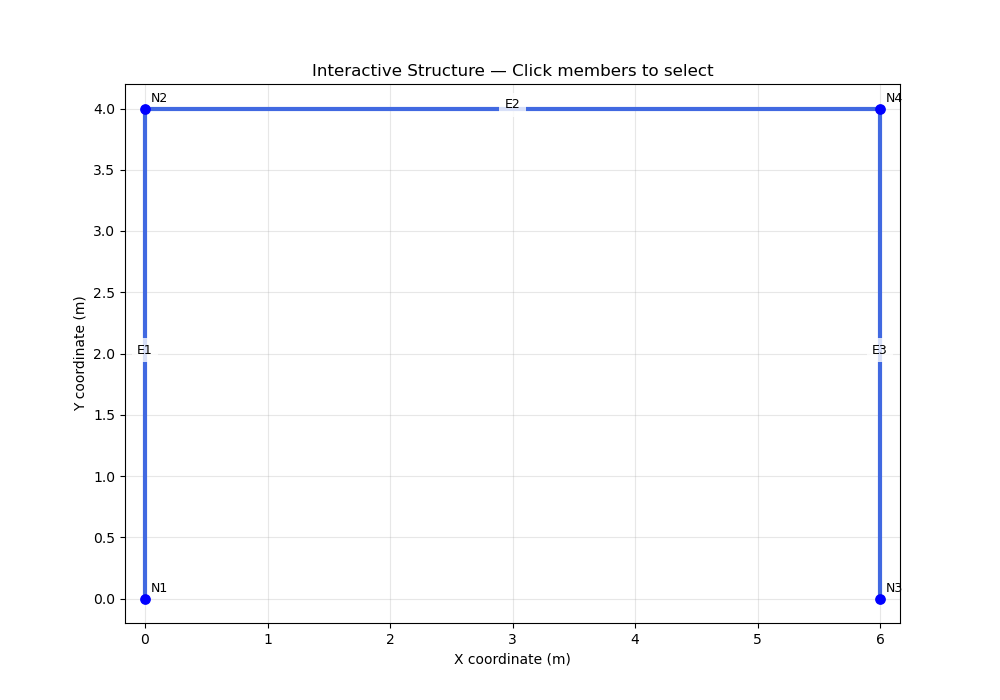

In [85]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# ============================================================
# INTERACTIVE SFD / BMD
# Click member to select; click again to deselect.
# Multiple members can be selected.
# Uses existing: nodes, elements, MEMBER_FORCES
# ============================================================

# -------------------- Validate inputs -----------------------
for var in ["nodes", "elements", "MEMBER_FORCES"]:
    if var not in globals():
        raise NameError(f"'{var}' is missing. Run your FEM cells first.")

selected_members = set()
diagram_artists = []
member_lines = {}

# -------------------- Read force results --------------------
def get_force_records(eid):
    """Extract local force vectors for an element, if available."""
    rec = MEMBER_FORCES.get(eid, MEMBER_FORCES.get(str(eid)))

    if rec is None:
        return []

    if isinstance(rec, dict):
        if "local_force" in rec:
            return [np.asarray(rec["local_force"], dtype=float).ravel()]
        return []

    if isinstance(rec, (list, tuple)):
        result = []
        for item in rec:
            if isinstance(item, dict) and "local_force" in item:
                result.append(
                    np.asarray(item["local_force"], dtype=float).ravel()
                )
        return result

    return []


def get_end_values(eid, diagram):
    records = get_force_records(eid)

    if not records:
        return None

    first, last = records[0], records[-1]

    if len(first) < 6 or len(last) < 6:
        return None

    # Assumed local force order:
    # [N_i, V_i, M_i, N_j, V_j, M_j]
    if diagram == "SFD":
        return float(first[1]), float(-last[4])

    return float(first[2]), float(last[5])


# -------------------- Create ONE figure ---------------------
fig, ax = plt.subplots(figsize=(10, 7))

for nid, xy in nodes.items():
    x, y = xy
    ax.scatter(x, y, color="blue", s=45, zorder=5)
    ax.annotate(
        f"N{nid}", (x, y),
        xytext=(4, 5), textcoords="offset points",
        fontsize=9
    )

for eid, (ni, nj) in enumerate(elements, start=1):
    xi, yi = nodes[ni]
    xj, yj = nodes[nj]

    line, = ax.plot(
        [xi, xj], [yi, yj],
        color="royalblue", linewidth=3, zorder=3
    )
    member_lines[eid] = line

    ax.text(
        (xi + xj) / 2, (yi + yj) / 2,
        f"E{eid}", fontsize=9, ha="center",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
        zorder=6
    )

ax.set_title("Interactive Structure — Click members to select")
ax.set_xlabel("X coordinate (m)")
ax.set_ylabel("Y coordinate (m)")
ax.grid(True, alpha=0.3)
ax.set_aspect("equal", adjustable="datalim")

# -------------------- Controls ------------------------------
diagram_choice = widgets.ToggleButtons(
    options=["SFD", "BMD"],
    description="Diagram:"
)

scale_slider = widgets.FloatSlider(
    value=0.15, min=0.02, max=0.5, step=0.01,
    description="Scale:", continuous_update=False
)

clear_button = widgets.Button(
    description="Clear selection",
    button_style="warning"
)

status = widgets.HTML("<b>Selected members:</b> none")
output = widgets.Output()


# -------------------- Find member at mouse location ---------
def find_member(event):
    if event.inaxes != ax or event.x is None or event.y is None:
        return None

    best_id = None
    best_distance = float("inf")

    for eid, (ni, nj) in enumerate(elements, start=1):
        p1 = ax.transData.transform(nodes[ni])
        p2 = ax.transData.transform(nodes[nj])
        pc = np.array([event.x, event.y], dtype=float)

        v = p2 - p1
        length2 = np.dot(v, v)
        if length2 < 1e-12:
            continue

        t = np.clip(np.dot(pc - p1, v) / length2, 0, 1)
        closest = p1 + t * v
        distance = np.linalg.norm(pc - closest)

        if distance < best_distance:
            best_distance = distance
            best_id = eid

    # Tolerance in screen pixels
    return best_id if best_distance <= 12 else None


# -------------------- Draw selected diagrams ----------------
def redraw_diagrams():
    global diagram_artists

    for artist in diagram_artists:
        try:
            artist.remove()
        except (ValueError, AttributeError):
            pass
    diagram_artists = []

    # Highlight selected members
    for eid, line in member_lines.items():
        if eid in selected_members:
            line.set_color("orange")
            line.set_linewidth(5)
        else:
            line.set_color("royalblue")
            line.set_linewidth(3)

    kind = diagram_choice.value
    scale = scale_slider.value

    with output:
        output.clear_output(wait=True)

        for eid in sorted(selected_members):
            ni, nj = elements[eid - 1]
            xi, yi = nodes[ni]
            xj, yj = nodes[nj]

            dx, dy = xj - xi, yj - yi
            L = np.hypot(dx, dy)
            if L <= 1e-12:
                continue

            values = get_end_values(eid, kind)

            if values is None:
                print(
                    f"E{eid}: local end forces unavailable. "
                    "Check MEMBER_FORCES structure and force convention."
                )
                continue

            v0, vL = values
            s = np.linspace(0, L, 80)
            v = np.linspace(v0, vL, len(s))

            # Local transverse direction
            nx, ny = -dy / L, dx / L

            vmax = max(np.max(np.abs(v)), 1e-12)
            offset = scale * L * v / vmax

            xp = xi + (s / L) * dx + nx * offset
            yp = yi + (s / L) * dy + ny * offset

            color = "crimson" if kind == "SFD" else "darkgreen"
            line, = ax.plot(
                xp, yp, color=color, linewidth=2.5, zorder=8
            )
            diagram_artists.append(line)

            # End values and largest absolute interpolated value
            for idx, label in [
                (0, f"{v[0]:.3g}"),
                (-1, f"{v[-1]:.3g}"),
                (int(np.argmax(np.abs(v))),
                 f"Max |{kind}|={np.max(np.abs(v)):.3g}")
            ]:
                ann = ax.annotate(
                    label, (xp[idx], yp[idx]),
                    xytext=(4, 5), textcoords="offset points",
                    fontsize=8, color=color,
                    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
                    zorder=9
                )
                diagram_artists.append(ann)

            print(
                f"E{eid} {kind}: start={v0:.5g}, "
                f"end={vL:.5g}, max absolute={np.max(np.abs(v)):.5g}"
            )

    status.value = (
        "<b>Selected members:</b> "
        + (", ".join(f"E{i}" for i in sorted(selected_members)) or "none")
    )
    ax.set_title(
        f"{kind} — Selected members: "
        + (", ".join(f"E{i}" for i in sorted(selected_members)) or "none")
    )
    fig.canvas.draw_idle()


# -------------------- Mouse click event --------------------
def on_click(event):
    eid = find_member(event)
    if eid is None:
        return

    if eid in selected_members:
        selected_members.remove(eid)
    else:
        selected_members.add(eid)

    redraw_diagrams()


fig.canvas.mpl_connect("button_press_event", on_click)


# -------------------- Controls callbacks --------------------
def clear_selection(_):
    selected_members.clear()
    redraw_diagrams()


clear_button.on_click(clear_selection)
diagram_choice.observe(redraw_diagrams, names="value")
scale_slider.observe(redraw_diagrams, names="value")


# -------------------- Display only once ---------------------
display(widgets.VBox([
    widgets.HBox([diagram_choice, scale_slider, clear_button]),
    status,
    output,
    fig.canvas
]))

# MEMBER-LEVEL FEM VISUALIZATION

In [31]:
%matplotlib widget

In [32]:
# ============================================================
# INTERACTIVE FEM MEMBER INSPECTOR
# Uses Plotly FigureWidget
#
# Works for:
#     TRUSS
#     BEAM
#     FRAME
#
# Click any member in the structure.
# Member-level information appears below.
# ============================================================

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display


# ============================================================
# 1. GET NODE COORDINATES
# ============================================================

def get_node_xy(node_id):

    n = FEM_MODEL["nodes"][node_id]

    # Case 1:
    # dictionary like {"x": ..., "y": ...}
    if isinstance(n, dict):

        return (
            float(n["x"]),
            float(n["y"])
        )

    # Case 2:
    # tuple/list like (x, y)
    return (
        float(n[0]),
        float(n[1])
    )


# ============================================================
# 2. CREATE COORDINATE DICTIONARY
# ============================================================

NODE_COORDINATES = {}

for node_id in NODE_IDS:

    NODE_COORDINATES[node_id] = get_node_xy(node_id)


# ============================================================
# 3. MEMBER INFORMATION
# ============================================================

def get_member_geometry(eid):

    g = ELEMENT_GEOMETRY[eid]

    i = g["i"]
    j = g["j"]

    xi, yi = NODE_COORDINATES[i]
    xj, yj = NODE_COORDINATES[j]

    L = float(g["L"])

    c = float(g["c"])
    s = float(g["s"])

    return {
        "i": i,
        "j": j,
        "xi": xi,
        "yi": yi,
        "xj": xj,
        "yj": yj,
        "L": L,
        "c": c,
        "s": s
    }


# ============================================================
# 4. GLOBAL DISPLACEMENTS
# ============================================================

def get_global_displacements(node_id):

    dofs = get_node_dofs(node_id)

    ux = float(DISPLACEMENTS[dofs[0]])
    uy = float(DISPLACEMENTS[dofs[1]])

    if DOF_PER_NODE == 3:

        rz = float(DISPLACEMENTS[dofs[2]])

        return ux, uy, rz

    return ux, uy, None


# ============================================================
# 5. LOCAL DISPLACEMENTS
# ============================================================

def get_local_displacements(eid):

    g = ELEMENT_GEOMETRY[eid]

    i = g["i"]
    j = g["j"]

    c = float(g["c"])
    s = float(g["s"])

    ui = get_global_displacements(i)
    uj = get_global_displacements(j)

    # --------------------------------------------------------
    # TRUSS
    # --------------------------------------------------------

    if ETYPE == "TRUSS":

        ux_i, uy_i, _ = ui
        ux_j, uy_j, _ = uj

        # Local axial displacement
        u_i = (
            c * ux_i +
            s * uy_i
        )

        u_j = (
            c * ux_j +
            s * uy_j
        )

        # Local transverse displacement
        v_i = (
            -s * ux_i +
            c * uy_i
        )

        v_j = (
            -s * ux_j +
            c * uy_j
        )

        return {
            "u_i": u_i,
            "v_i": v_i,
            "u_j": u_j,
            "v_j": v_j,
            "rz_i": None,
            "rz_j": None
        }

    # --------------------------------------------------------
    # BEAM / FRAME
    # --------------------------------------------------------

    ux_i, uy_i, rz_i = ui
    ux_j, uy_j, rz_j = uj

    u_i = (
        c * ux_i +
        s * uy_i
    )

    v_i = (
        -s * ux_i +
        c * uy_i
    )

    u_j = (
        c * ux_j +
        s * uy_j
    )

    v_j = (
        -s * ux_j +
        c * uy_j
    )

    return {
        "u_i": u_i,
        "v_i": v_i,
        "u_j": u_j,
        "v_j": v_j,
        "rz_i": rz_i,
        "rz_j": rz_j
    }


# ============================================================
# 6. GET MEMBER FORCES
# ============================================================

def get_member_force_data(eid):

    result = MEMBER_FORCES[eid]

    f = np.asarray(
        result["local_force"],
        dtype=float
    ).flatten()

    # --------------------------------------------------------
    # TRUSS
    # --------------------------------------------------------

    if ETYPE == "TRUSS":

        axial_i = float(f[0])

        # Usually j-end is equal and opposite
        axial_j = float(f[2])

        # Use average magnitude for display
        axial = (
            abs(axial_i) +
            abs(axial_j)
        ) / 2.0

        # Determine sign from i-end force
        signed_axial = axial_i

        if abs(signed_axial) < 1e-12:

            state = "ZERO FORCE"

        elif signed_axial > 0:

            state = "TENSION"

        else:

            state = "COMPRESSION"

        return {
            "axial": signed_axial,
            "axial_i": axial_i,
            "axial_j": axial_j,
            "state": state,
            "shear_i": None,
            "shear_j": None,
            "moment_i": None,
            "moment_j": None
        }

    # --------------------------------------------------------
    # BEAM / FRAME
    # --------------------------------------------------------

    fx_i = float(f[0])
    fy_i = float(f[1])
    mz_i = float(f[2])

    fx_j = float(f[3])
    fy_j = float(f[4])
    mz_j = float(f[5])

    return {
        "axial": None,
        "axial_i": fx_i,
        "axial_j": fx_j,
        "state": None,
        "shear_i": fy_i,
        "shear_j": fy_j,
        "moment_i": mz_i,
        "moment_j": mz_j
    }


# ============================================================
# 7. FORMAT NUMBER
# ============================================================

def fmt(value):

    if value is None:
        return "N/A"

    if abs(value) < 1e-12:
        value = 0.0

    return f"{value:.6e}"


# ============================================================
# 8. CREATE FIGURE
# ============================================================

fig = make_subplots(
    rows=2,
    cols=1,
    row_heights=[0.58, 0.42],
    vertical_spacing=0.08
)


# ============================================================
# 9. DRAW STRUCTURE
# ============================================================

member_trace_indices = {}


for eid in range(
    1,
    len(FEM_MODEL["elements"]) + 1
):

    gm = get_member_geometry(eid)

    # Every member gets its OWN Plotly trace.
    # This is what makes individual clicking possible.

    trace_index = len(fig.data)

    fig.add_trace(
        go.Scatter(
            x=[
                gm["xi"],
                gm["xj"]
            ],

            y=[
                gm["yi"],
                gm["yj"]
            ],

            mode="lines",

            line=dict(
                width=5
            ),

            name=f"E{eid}",

            customdata=[eid, eid],

            hovertemplate=(
                f"<b>MEMBER E{eid}</b><br>"
                f"i-node = N{gm['i']}<br>"
                f"j-node = N{gm['j']}<br>"
                f"Length = {gm['L']:.6f} m"
                "<extra></extra>"
            )
        ),
        row=1,
        col=1
    )

    member_trace_indices[eid] = trace_index


# ============================================================
# 10. DRAW NODES
# ============================================================

node_x = []
node_y = []
node_text = []

for node_id in NODE_IDS:

    x, y = NODE_COORDINATES[node_id]

    node_x.append(x)
    node_y.append(y)
    node_text.append(f"N{node_id}")


fig.add_trace(
    go.Scatter(
        x=node_x,
        y=node_y,

        mode="markers+text",

        text=node_text,

        textposition="top center",

        marker=dict(
            size=11
        ),

        name="Nodes",

        hovertemplate=(
            "<b>%{text}</b>"
            "<extra></extra>"
        )
    ),
    row=1,
    col=1
)


# ============================================================
# 11. MEMBER LABELS
# ============================================================

for eid in range(
    1,
    len(FEM_MODEL["elements"]) + 1
):

    gm = get_member_geometry(eid)

    xm = (
        gm["xi"] +
        gm["xj"]
    ) / 2.0

    ym = (
        gm["yi"] +
        gm["yj"]
    ) / 2.0

    fig.add_annotation(
        x=xm,
        y=ym,

        text=f"E{eid}",

        showarrow=False,

        bgcolor="white",

        font=dict(
            size=12
        ),

        row=1,
        col=1
    )


# ============================================================
# 12. EMPTY MEMBER DETAIL AREA
# ============================================================

fig.add_trace(
    go.Scatter(
        x=[0, 1],
        y=[0, 0],

        mode="lines",

        line=dict(
            width=6
        ),

        hoverinfo="skip",

        showlegend=False
    ),
    row=2,
    col=1
)


# ============================================================
# 13. DEFAULT DETAIL TEXT
# ============================================================

fig.add_annotation(
    x=0.5,
    y=0.5,

    xref="x2 domain",
    yref="y2 domain",

    text=(
        "<b>CLICK ANY MEMBER ABOVE</b><br><br>"
        "Member-level FEM results will appear here."
    ),

    showarrow=False,

    font=dict(
        size=16
    ),

    align="center",

    row=2,
    col=1
)


# ============================================================
# 14. FIGURE SETTINGS
# ============================================================

fig.update_layout(

    title=(
        "FEM STRUCTURE — CLICK A MEMBER"
    ),

    height=850,

    showlegend=False,

    hovermode="closest",

    margin=dict(
        l=60,
        r=60,
        t=70,
        b=50
    )
)


fig.update_xaxes(
    title_text="X (m)",
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Y (m)",
    scaleanchor="x",
    scaleratio=1,
    row=1,
    col=1
)

fig.update_xaxes(
    visible=False,
    row=2,
    col=1
)

fig.update_yaxes(
    visible=False,
    row=2,
    col=1
)


# ============================================================
# 15. MEMBER CLICK FUNCTION
# ============================================================

def show_member_details(trace, points, selector):

    if not points.point_inds:
        return

    # --------------------------------------------------------
    # Find which member was clicked
    # --------------------------------------------------------

    clicked_trace = points.trace_index

    selected_eid = None

    for eid, index in member_trace_indices.items():

        if index == clicked_trace:

            selected_eid = eid
            break

    if selected_eid is None:
        return


    eid = selected_eid

    gm = get_member_geometry(eid)

    local = get_local_displacements(eid)

    forces = get_member_force_data(eid)


    # ========================================================
    # HIGHLIGHT SELECTED MEMBER
    # ========================================================

    for member_id, trace_index in member_trace_indices.items():

        if member_id == eid:

            fig.data[trace_index].line.width = 8

        else:

            fig.data[trace_index].line.width = 3


    # ========================================================
    # UPDATE MEMBER-LEVEL LINE
    # ========================================================

    # Find the detail trace.
    # It is the trace immediately after all member traces
    # and node trace.

    detail_trace_index = (
        len(FEM_MODEL["elements"]) + 1
    )

    fig.data[detail_trace_index].x = [
        0,
        gm["L"]
    ]

    fig.data[detail_trace_index].y = [
        0,
        0
    ]


    # ========================================================
    # CLEAR OLD DETAIL ANNOTATIONS
    # ========================================================

    # Keep structure member labels.
    # Remove only annotations associated with row 2.

    remaining_annotations = []

    for ann in fig.layout.annotations:

        if getattr(ann, "xref", "") == "x2 domain":

            continue

        remaining_annotations.append(ann)

    fig.layout.annotations = remaining_annotations


    # ========================================================
    # MEMBER DETAIL TITLE
    # ========================================================

    fig.add_annotation(
        x=gm["L"] / 2,
        y=0,

        xref="x2",
        yref="y2",

        text=(
            f"<b>MEMBER E{eid} — N{gm['i']} → N{gm['j']}</b>"
        ),

        showarrow=False,

        yshift=25,

        font=dict(
            size=16
        ),

        row=2,
        col=1
    )


    # ========================================================
    # i / j NODE LABELS
    # ========================================================

    fig.add_annotation(
        x=0,
        y=0,

        xref="x2",
        yref="y2",

        text=f"<b>i = N{gm['i']}</b>",

        showarrow=False,

        yshift=45,

        xanchor="left",

        row=2,
        col=1
    )


    fig.add_annotation(
        x=gm["L"],
        y=0,

        xref="x2",
        yref="y2",

        text=f"<b>j = N{gm['j']}</b>",

        showarrow=False,

        yshift=45,

        xanchor="right",

        row=2,
        col=1
    )


    # ========================================================
    # LOCAL +X
    # ========================================================

    fig.add_annotation(
        x=gm["L"] * 0.75,
        y=0,

        xref="x2",
        yref="y2",

        text="local +X →",

        showarrow=False,

        yshift=-25,

        font=dict(
            size=12
        ),

        row=2,
        col=1
    )


    # ========================================================
    # BUILD DETAIL TEXT
    # ========================================================

    detail_text = (
        f"<b>MEMBER E{eid}</b><br>"
        f"i-node = N{gm['i']}<br>"
        f"j-node = N{gm['j']}<br>"
        f"Length = {gm['L']:.6f} m"
        "<br><br>"
    )


    # ========================================================
    # LOCAL DISPLACEMENTS
    # ========================================================

    detail_text += (
        "<b>LOCAL DISPLACEMENT</b><br>"
        f"u_i = {fmt(local['u_i'])} m"
        "&nbsp;&nbsp;&nbsp;&nbsp;"
        f"u_j = {fmt(local['u_j'])} m"
        "<br>"
        f"v_i = {fmt(local['v_i'])} m"
        "&nbsp;&nbsp;&nbsp;&nbsp;"
        f"v_j = {fmt(local['v_j'])} m"
        "<br>"
    )


    # ========================================================
    # GLOBAL DISPLACEMENTS
    # ========================================================

    ui = get_global_displacements(gm["i"])
    uj = get_global_displacements(gm["j"])

    detail_text += (
        "<br>"
        "<b>GLOBAL DISPLACEMENT</b><br>"
        f"UX_i = {fmt(ui[0])} m"
        "&nbsp;&nbsp;&nbsp;&nbsp;"
        f"UX_j = {fmt(uj[0])} m"
        "<br>"
        f"UY_i = {fmt(ui[1])} m"
        "&nbsp;&nbsp;&nbsp;&nbsp;"
        f"UY_j = {fmt(uj[1])} m"
        "<br>"
    )


    # ========================================================
    # ROTATION FOR BEAM / FRAME
    # ========================================================

    if ETYPE != "TRUSS":

        detail_text += (
            f"RZ_i = {fmt(ui[2])} rad"
            "&nbsp;&nbsp;&nbsp;&nbsp;"
            f"RZ_j = {fmt(uj[2])} rad"
            "<br>"
        )


    # ========================================================
    # TRUSS RESULTS
    # ========================================================

    if ETYPE == "TRUSS":

        detail_text += (
            "<br>"
            f"<b>AXIAL FORCE = {forces['axial']:.6f} kN</b><br>"
            f"<b>STATE = {forces['state']}</b><br>"
            "<br>"
            "<b>MOMENT = N/A for TRUSS</b>"
        )


    # ========================================================
    # BEAM / FRAME RESULTS
    # ========================================================

    else:

        detail_text += (
            "<br>"
            "<b>MEMBER END FORCES</b><br>"
            f"FX_i = {fmt(forces['axial_i'])} kN"
            "&nbsp;&nbsp;&nbsp;&nbsp;"
            f"FX_j = {fmt(forces['axial_j'])} kN"
            "<br>"
            f"FY_i = {fmt(forces['shear_i'])} kN"
            "&nbsp;&nbsp;&nbsp;&nbsp;"
            f"FY_j = {fmt(forces['shear_j'])} kN"
            "<br>"
            f"MZ_i = {fmt(forces['moment_i'])} kN·m"
            "&nbsp;&nbsp;&nbsp;&nbsp;"
            f"MZ_j = {fmt(forces['moment_j'])} kN·m"
        )


    # ========================================================
    # SHOW DETAIL TEXT
    # ========================================================

    fig.add_annotation(

        x=0.02,
        y=0.48,

        xref="x2 domain",
        yref="y2 domain",

        text=detail_text,

        showarrow=False,

        align="left",

        xanchor="left",
        yanchor="middle",

        font=dict(
            family="Courier New",
            size=12
        ),

        row=2,
        col=1
    )


    # ========================================================
    # UPDATE DETAIL AXIS
    # ========================================================

    fig.update_xaxes(
        range=[
            -0.10 * gm["L"],
            1.10 * gm["L"]
        ],
        row=2,
        col=1
    )

    fig.update_yaxes(
        range=[
            -1.5,
            1.5
        ],
        row=2,
        col=1
    )


# ============================================================
# 16. CONNECT CLICK CALLBACK
# ============================================================

for eid, trace_index in member_trace_indices.items():

    fig.data[trace_index].on_click(
        show_member_details
    )


# ============================================================
# 17. DISPLAY ONLY ONE FIGURE
# ============================================================

display(fig)

In [45]:
%pip install --upgrade anywidget plotly ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [33]:
# ============================================================
# INTERACTIVE FEM MEMBER INSPECTOR
# ============================================================
#
# ONE STRUCTURE
# CLICK ANY MEMBER
# MEMBER-LEVEL INFORMATION APPEARS BELOW
#
# Compatible with:
#       TRUSS
#       BEAM
#       FRAME
#
# Requires:
#       plotly
#       anywidget
#       ipywidgets
#
# ============================================================

import numpy as np
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display


# ============================================================
# 1. GET NODE COORDINATES
# ============================================================

def get_node_xy(node_id):

    n = FEM_MODEL["nodes"][node_id]

    # --------------------------------------------------------
    # Dictionary format
    # --------------------------------------------------------

    if isinstance(n, dict):

        x = n.get("x", n.get("X"))
        y = n.get("y", n.get("Y"))

        return float(x), float(y)

    # --------------------------------------------------------
    # Tuple/list format
    #
    # Example:
    # FEM_MODEL["nodes"][1] = (0, 0)
    # --------------------------------------------------------

    if isinstance(n, (tuple, list, np.ndarray)):

        return float(n[0]), float(n[1])

    raise TypeError(
        f"Unsupported node format for Node {node_id}: {type(n)}"
    )


# ============================================================
# 2. GET ELEMENT CONNECTIVITY
# ============================================================

def get_element_nodes(eid):

    g = ELEMENT_GEOMETRY[eid]

    return int(g["i"]), int(g["j"])


# ============================================================
# 3. SAFE NUMBER FORMAT
# ============================================================

def fmt(value):

    try:
        return f"{float(value):.6e}"
    except Exception:
        return "N/A"


# ============================================================
# 4. GET GLOBAL DISPLACEMENTS
# ============================================================

def get_global_displacement(node_id):

    dofs = get_node_dofs(node_id)

    values = [
        float(DISPLACEMENTS[dof])
        for dof in dofs
    ]

    if DOF_PER_NODE == 2:

        return {
            "UX": values[0],
            "UY": values[1]
        }

    else:

        return {
            "UX": values[0],
            "UY": values[1],
            "RZ": values[2]
        }


# ============================================================
# 5. GET MEMBER FORCE RESULT
# ============================================================

def get_member_result(eid):

    if eid not in MEMBER_FORCES:

        return None

    return MEMBER_FORCES[eid]


# ============================================================
# 6. CREATE MEMBER INFORMATION
# ============================================================

def make_member_text(eid):

    i, j = get_element_nodes(eid)

    xi, yi = get_node_xy(i)
    xj, yj = get_node_xy(j)

    dx = xj - xi
    dy = yj - yi

    L = float(
        np.sqrt(
            dx**2 +
            dy**2
        )
    )

    c = dx / L
    s = dy / L

    ui = get_global_displacement(i)
    uj = get_global_displacement(j)

    result = get_member_result(eid)

    # ========================================================
    # TRUSS
    # ========================================================

    if ETYPE == "TRUSS":

        axial = 0.0

        if result is not None:

            f = result.get(
                "local_force",
                result.get("forces", None)
            )

            if f is not None:

                axial = float(f[0])


        # ----------------------------------------------------
        # State
        # ----------------------------------------------------

        tolerance = 1e-9

        if axial > tolerance:

            state = "TENSION"

        elif axial < -tolerance:

            state = "COMPRESSION"

        else:

            state = "ZERO FORCE"


        # ----------------------------------------------------
        # Local displacements
        # ----------------------------------------------------

        u_i = (
            c * ui["UX"]
            + s * ui["UY"]
        )

        v_i = (
            -s * ui["UX"]
            + c * ui["UY"]
        )

        u_j = (
            c * uj["UX"]
            + s * uj["UY"]
        )

        v_j = (
            -s * uj["UX"]
            + c * uj["UY"]
        )


        text = f"""
MEMBER E{eid}     —     N{i} → N{j}

i-node = N{i}                         j-node = N{j}
Length = {L:.6f} m

                         local +X →
i-node ●────────────────────────────────● j-node
      N{i}                              N{j}


LOCAL DISPLACEMENT

u_i = {fmt(u_i)} m              u_j = {fmt(u_j)} m
v_i = {fmt(v_i)} m              v_j = {fmt(v_j)} m


GLOBAL DISPLACEMENT

UX_i = {fmt(ui["UX"])} m        UX_j = {fmt(uj["UX"])} m
UY_i = {fmt(ui["UY"])} m        UY_j = {fmt(uj["UY"])} m


AXIAL FORCE = {axial:.6f} kN

STATE = {state}

MOMENT = N/A for TRUSS
"""

        return text


    # ========================================================
    # BEAM / FRAME
    # ========================================================

    f = None

    if result is not None:

        f = result.get(
            "local_force",
            result.get("forces", None)
        )


    # --------------------------------------------------------
    # Default forces
    # --------------------------------------------------------

    if f is None:

        f = np.zeros(6)


    f = np.asarray(f, dtype=float)


    # --------------------------------------------------------
    # Local displacement transformation
    # --------------------------------------------------------

    def local_disp(d):

        ux = d["UX"]
        uy = d["UY"]
        rz = d["RZ"]

        u = (
            c * ux
            + s * uy
        )

        v = (
            -s * ux
            + c * uy
        )

        return u, v, rz


    u_i, v_i, rz_i = local_disp(ui)
    u_j, v_j, rz_j = local_disp(uj)


    # --------------------------------------------------------
    # Local end forces
    # --------------------------------------------------------

    FX_i = f[0]
    FY_i = f[1]
    MZ_i = f[2]

    FX_j = f[3]
    FY_j = f[4]
    MZ_j = f[5]


    text = f"""
MEMBER E{eid}     —     N{i} → N{j}

i-node = N{i}                         j-node = N{j}
Length = {L:.6f} m

                         local +X →
i-node ●════════════════════════════════● j-node
      N{i}                              N{j}


LOCAL DISPLACEMENT

u_i  = {fmt(u_i)} m          u_j  = {fmt(u_j)} m
v_i  = {fmt(v_i)} m          v_j  = {fmt(v_j)} m

θ_i  = {fmt(rz_i)} rad       θ_j  = {fmt(rz_j)} rad


GLOBAL DISPLACEMENT

UX_i = {fmt(ui["UX"])} m     UX_j = {fmt(uj["UX"])} m
UY_i = {fmt(ui["UY"])} m     UY_j = {fmt(uj["UY"])} m
RZ_i = {fmt(rz_i)} rad       RZ_j = {fmt(rz_j)} rad


LOCAL END FORCES

                 i-end                    j-end

FX       = {FX_i: .6f} kN       FX       = {FX_j: .6f} kN
FY       = {FY_i: .6f} kN       FY       = {FY_j: .6f} kN
MZ       = {MZ_i: .6f} kN·m     MZ       = {MZ_j: .6f} kN·m
"""

    return text


# ============================================================
# 7. CREATE FIGURE WIDGET
# ============================================================

fig = go.FigureWidget()


# ============================================================
# 8. ADD MEMBERS
# ============================================================

member_trace_map = {}


for eid in range(
    1,
    len(FEM_MODEL["elements"]) + 1
):

    i, j = get_element_nodes(eid)

    xi, yi = get_node_xy(i)
    xj, yj = get_node_xy(j)


    # --------------------------------------------------------
    # Main visible member
    # --------------------------------------------------------

    trace = go.Scatter(

        x=[xi, xj],

        y=[yi, yj],

        mode="lines",

        line=dict(
            width=5
        ),

        name=f"E{eid}",

        customdata=[eid, eid],

        hovertemplate=(
            f"<b>MEMBER E{eid}</b><br>"
            f"N{i} → N{j}<br>"
            f"Click to inspect"
            "<extra></extra>"
        ),

        showlegend=False
    )


    fig.add_trace(trace)

    member_trace_map[eid] = len(fig.data) - 1


# ============================================================
# 9. ADD NODES
# ============================================================

node_x = []
node_y = []
node_text = []

for node in NODE_IDS:

    x, y = get_node_xy(node)

    node_x.append(x)
    node_y.append(y)

    node_text.append(
        f"N{node}"
    )


fig.add_trace(
    go.Scatter(

        x=node_x,

        y=node_y,

        mode="markers+text",

        marker=dict(
            size=10
        ),

        text=node_text,

        textposition="top center",

        hoverinfo="skip",

        showlegend=False
    )
)


# ============================================================
# 10. FIGURE LAYOUT
# ============================================================

fig.update_layout(

    title=dict(
        text="FEM STRUCTURE — CLICK ANY MEMBER",
        x=0.5
    ),

    xaxis=dict(
        title="X (m)",
        showgrid=True,
        zeroline=False
    ),

    yaxis=dict(
        title="Y (m)",
        showgrid=True,
        zeroline=False,
        scaleanchor="x",
        scaleratio=1
    ),

    height=600,

    margin=dict(
        l=60,
        r=40,
        t=70,
        b=60
    ),

    hovermode="closest",

    template="plotly_white"
)


# ============================================================
# 11. MEMBER INFORMATION OUTPUT
# ============================================================

member_output = widgets.Output()


# ============================================================
# 12. CLICK CALLBACK
# ============================================================

def member_clicked(trace, points, selector):

    if len(points.point_inds) == 0:

        return


    # --------------------------------------------------------
    # Determine which member was clicked
    # --------------------------------------------------------

    point_index = points.point_inds[0]

    eid = int(
        trace.customdata[point_index]
    )


    # --------------------------------------------------------
    # Clear previous information
    # --------------------------------------------------------

    with member_output:

        member_output.clear_output(
            wait=True
        )

        print(
            make_member_text(eid)
        )


# ============================================================
# 13. CONNECT CLICK EVENTS
# ============================================================

for eid, trace_index in member_trace_map.items():

    fig.data[trace_index].on_click(
        member_clicked
    )


# ============================================================
# 14. DISPLAY ONLY ONE STRUCTURE
# ============================================================

display(fig)

display(
    widgets.HTML(
        "<h3 style='margin-top:15px;'>"
        "MEMBER RESULTS"
        "</h3>"
    )
)

display(member_output)

FigureWidget({
    'data': [{'customdata': [1, 1],
              'hovertemplate': '<b>MEMBER E1</b><br>N2 → N1<br>Click to inspect<extra></extra>',
              'line': {'width': 5},
              'mode': 'lines',
              'name': 'E1',
              'showlegend': False,
              'type': 'scatter',
              'uid': '2444ddf3-02b5-4444-b82d-46a7a859919c',
              'x': [3.0, 0.0],
              'y': [4.0, 0.0]},
             {'customdata': [2, 2],
              'hovertemplate': '<b>MEMBER E2</b><br>N2 → N3<br>Click to inspect<extra></extra>',
              'line': {'width': 5},
              'mode': 'lines',
              'name': 'E2',
              'showlegend': False,
              'type': 'scatter',
              'uid': '5a6c0a2c-ab2c-4b4a-9894-2e27a574a1d4',
              'x': [3.0, 6.0],
              'y': [4.0, 4.0]},
             {'customdata': [3, 3],
              'hovertemplate': '<b>MEMBER E3</b><br>N3 → N4<br>Click to inspect<extra></extra>',
            

HTML(value="<h3 style='margin-top:15px;'>MEMBER RESULTS</h3>")

Output()